In [1]:
import ROOT
from scipy.optimize import minimize
import matplotlib.pyplot as plt

In [2]:
# filePath = "/d/home/septian/Moments2Amplitudes/runs/H_odd_model_initializedBWa2_initializedSWaves_FitAllBWPi1/"
# fileName = "result_tree_allMoments_BWa2_initializedSWaves_Fit_AllBWPi1_1858_nominal_t010030.root"
out_pdf_dir = "/d/home/septian/EtaPi0Plot/"

In [3]:
filePath = "/d/home/septian/Moments2Amplitudes/run/Mom2Amps_H_two_model_seq_init/"
fileName = "result_tree_H_two_model_seq_init_nominal_t010030_firstbin_0.820000.root"

In [4]:
file = ROOT.TFile.Open(filePath + fileName)
file.ls()

TFile**		/d/home/septian/Moments2Amplitudes/run/Mom2Amps_H_two_model_seq_init/result_tree_H_two_model_seq_init_nominal_t010030_firstbin_0.820000.root	
 TFile*		/d/home/septian/Moments2Amplitudes/run/Mom2Amps_H_two_model_seq_init/result_tree_H_two_model_seq_init_nominal_t010030_firstbin_0.820000.root	
  KEY: TTree	result;1	result
  KEY: TTree	mass_dependent_params;1	Mass Dependent Parameters
  KEY: TTree	chi2;1	chi2


In [5]:
resultTree = file.Get("result")
resultTree.Print()

******************************************************************************
*Tree    :result    : result                                                 *
*Entries :       20 : Total =           85211 bytes  File  Size =      22613 *
*        :          : Tree compression factor =   1.50                       *
******************************************************************************
*Br    0 :mass_bin  : mass_bin/D                                             *
*Entries :       20 : Total  Size=        742 bytes  File Size  =        224 *
*Baskets :        1 : Basket Size=      32000 bytes  Compression=   1.06     *
*............................................................................*
*Br    1 :a_0_0     : a_0_0/D                                                *
*Entries :       20 : Total  Size=        727 bytes  File Size  =        234 *
*Baskets :        1 : Basket Size=      32000 bytes  Compression=   1.00     *
*...................................................

In [6]:
df_result = ROOT.RDataFrame(resultTree)

col_names = df_result.GetColumnNames()
for name in col_names:
    print(name)

H_0_0_0
H_0_1_0
H_0_1_1
H_0_2_0
H_0_2_1
H_0_2_2
H_0_3_0
H_0_3_1
H_0_3_2
H_0_3_3
H_0_4_0
H_0_4_1
H_0_4_2
H_0_4_3
H_0_4_4
H_1_0_0
H_1_1_0
H_1_1_1
H_1_2_0
H_1_2_1
H_1_2_2
H_1_3_0
H_1_3_1
H_1_3_2
H_1_3_3
H_1_4_0
H_1_4_1
H_1_4_2
H_1_4_3
H_1_4_4
H_2_1_1
H_2_2_1
H_2_2_2
H_2_3_1
H_2_3_2
H_2_3_3
H_2_4_1
H_2_4_2
H_2_4_3
H_2_4_4
a_0_0
a_0_0_error
a_1_-1
a_1_-1_error
a_1_0
a_1_0_error
a_1_1
a_1_1_error
a_2_-1
a_2_-1_error
a_2_-2
a_2_-2_error
a_2_0
a_2_0_error
a_2_1
a_2_1_error
a_2_2
a_2_2_error
aphi_0_0
aphi_0_0_error
aphi_1_-1
aphi_1_-1_error
aphi_1_0
aphi_1_0_error
aphi_1_1
aphi_1_1_error
aphi_2_-1
aphi_2_-1_error
aphi_2_-2
aphi_2_-2_error
aphi_2_0
aphi_2_0_error
aphi_2_1
aphi_2_1_error
aphi_2_2
aphi_2_2_error
b_0_0
b_0_0_error
b_1_-1
b_1_-1_error
b_1_0
b_1_0_error
b_1_1
b_1_1_error
b_2_-1
b_2_-1_error
b_2_-2
b_2_-2_error
b_2_0
b_2_0_error
b_2_1
b_2_1_error
b_2_2
b_2_2_error
bphi_0_0
bphi_0_0_error
bphi_1_-1
bphi_1_-1_error
bphi_1_0
bphi_1_0_error
bphi_1_1
bphi_1_1_error
bphi_2_-1
bphi_2_-1_erro

In [7]:
# Construct complex data points from magnitude and phase columns
df_result = df_result.Define("a_0_0_real" , "a_0_0*TMath::Cos(aphi_0_0)")
df_result = df_result.Define("a_0_0_imag" , "a_0_0*TMath::Sin(aphi_0_0)")
df_result = df_result.Define("b_0_0_real" , "b_0_0*TMath::Cos(bphi_0_0)")
df_result = df_result.Define("b_0_0_imag" , "b_0_0*TMath::Sin(bphi_0_0)")

In [8]:
df_result.AsNumpy(["mass_bin"])["mass_bin"]

ndarray([0.82, 0.86, 0.9 , 0.94, 0.98, 1.02, 1.06, 1.1 , 1.14, 1.18, 1.22,
         1.26, 1.3 , 1.34, 1.38, 1.42, 1.46, 1.5 , 1.54, 1.58])

In [9]:
# Fit the conformal polynomial to the complex data points

import numpy as np

def conformal_polynomial(z, *params):
    """Conformal polynomial expansion in z."""
    result = np.zeros_like(z, dtype=np.complex_)
    for n, p in enumerate(params):
        result += p * z**n
    return result

# Define conformal mapping
def conformal_map(s, s_min, s_0):
    """Conformal mapping from s to z.  
    Parameters:
    -----------
    s : float or array
        Invariant mass squared (m²)
    s_min : float
        Threshold (typically (2*m_π)² = 0.28 GeV² for ππ)
    s_0 : float
        Expansion point (e.g., 0.96 GeV² for f₀(980))
    
    Returns:
    --------
    z : complex
        Conformal variable, |z| < 1 for physical region
    """
    sqrt_s = np.sqrt(s)
    sqrt_s0_minus_smin = np.sqrt(s_0 - s_min)
    
    z = (sqrt_s - sqrt_s0_minus_smin) / (sqrt_s + sqrt_s0_minus_smin)
    
    return z

In [10]:
# Extract data for fitting
masses = np.array(df_result.AsNumpy(["mass_bin"])["mass_bin"])

a_real = np.array(df_result.AsNumpy(["a_0_0_real"])["a_0_0_real"])
a_imag = np.array(df_result.AsNumpy(["a_0_0_imag"])["a_0_0_imag"])
a_complex = a_real + 1j * a_imag

b_real = np.array(df_result.AsNumpy(["b_0_0_real"])["b_0_0_real"])
b_imag = np.array(df_result.AsNumpy(["b_0_0_imag"])["b_0_0_imag"])
b_complex = b_real + 1j * b_imag

In [11]:
# Check data values to understand scale
print(f"Number of data points: {len(masses)}")
print(f"\nMass range: {masses.min():.3f} - {masses.max():.3f} GeV")
print(f"\na_0_0 amplitude:")
print(f"  Magnitude range: {np.abs(a_complex).min():.2e} - {np.abs(a_complex).max():.2e}")
print(f"  Real part range: {a_real.min():.2e} - {a_real.max():.2e}")
print(f"  Imag part range: {a_imag.min():.2e} - {a_imag.max():.2e}")
print(f"\nFirst few data points:")
for i in range(min(5, len(masses))):
    print(f"  m={masses[i]:.3f}: a_0_0 = {a_complex[i]:.4e}")

Number of data points: 20

Mass range: 0.820 - 1.580 GeV

a_0_0 amplitude:
  Magnitude range: 5.12e+01 - 2.93e+02
  Real part range: -1.98e+02 - 2.16e+02
  Imag part range: -3.06e+01 - 2.92e+02

First few data points:
  m=0.820: a_0_0 = -2.7891e+00+5.1162e+01j
  m=0.860: a_0_0 = 2.7012e+01+6.8101e+01j
  m=0.900: a_0_0 = 2.2963e+01+1.1965e+02j
  m=0.940: a_0_0 = 4.1362e+01+1.8582e+02j
  m=0.980: a_0_0 = 1.0331e+01+2.9205e+02j


In [12]:
# Check for error columns
print("\nLooking for error columns:")
for name in col_names:
    name_str = str(name)
    if 'err' in name_str.lower() or 'error' in name_str.lower() or 'unc' in name_str.lower():
        print(f"  {name_str}")


Looking for error columns:
  a_0_0_error
  a_1_-1_error
  a_1_0_error
  a_1_1_error
  a_2_-1_error
  a_2_-2_error
  a_2_0_error
  a_2_1_error
  a_2_2_error
  aphi_0_0_error
  aphi_1_-1_error
  aphi_1_0_error
  aphi_1_1_error
  aphi_2_-1_error
  aphi_2_-2_error
  aphi_2_0_error
  aphi_2_1_error
  aphi_2_2_error
  b_0_0_error
  b_1_-1_error
  b_1_0_error
  b_1_1_error
  b_2_-1_error
  b_2_-2_error
  b_2_0_error
  b_2_1_error
  b_2_2_error
  bphi_0_0_error
  bphi_1_-1_error
  bphi_1_0_error
  bphi_1_1_error
  bphi_2_-1_error
  bphi_2_-2_error
  bphi_2_0_error
  bphi_2_1_error
  bphi_2_2_error


In [13]:
# # Check conformal mapping behavior
# print("Conformal mapping analysis:")
# print(f"s_min = {s_min:.4f} GeV² (threshold)")
# print(f"s_0 = {s_0:.4f} GeV²")
# print(f"\nAt s = s_0: z = {conformal_map(s_0, s_min, s_0):.4f}")
# print(f"At s = s_min: z = {conformal_map(s_min, s_min, s_0):.4f}")
# print(f"At s → ∞: z → 1")
# print(f"\nFor our data:")
# print(f"z values: {z_values}")
# print(f"|z| range: [{np.abs(z_values).min():.4f}, {np.abs(z_values).max():.4f}]")

# # Check if the polynomial can even reach the data scale
# print(f"\nData amplitude scale: ~{np.abs(a_complex).mean():.1f}")
# print(f"If all polynomial coefficients are O(1), with z ~ 0.5-0.8:")
# print(f"  Order 1: a_0 + a_1*z ~ O(1)")
# print(f"  Order 5: sum(a_i * z^i) ~ O(1)")
# print(f"\nThe polynomial needs coefficients ~ O(100) to match data!")

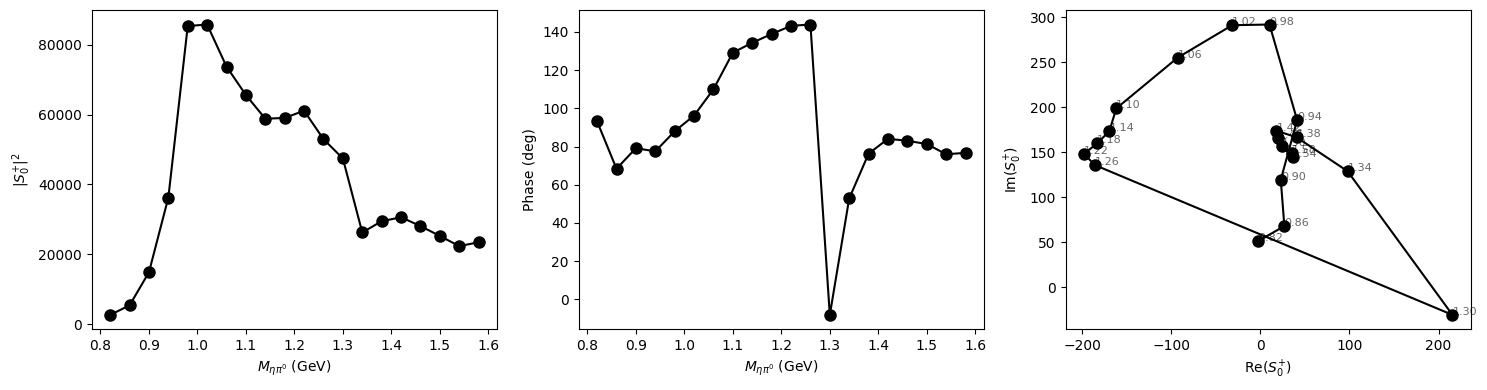

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(masses, np.abs(a_complex)**2, 'ko-', markersize=8)
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)')
ax.set_ylabel(r'$|S_0^{+}|^2$')
ax.set_title('')

ax = axes[1]
ax.plot(masses, np.angle(a_complex, deg=True), 'ko-', markersize=8)
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)')
ax.set_ylabel('Phase (deg)')
ax.set_title('')

ax = axes[2]
ax.plot(a_complex.real, a_complex.imag, 'ko-', markersize=8)
for i in range(len(masses)):
    ax.annotate(f'{masses[i]:.2f}', (a_complex.real[i], a_complex.imag[i]), 
                fontsize=8, alpha=0.6)
ax.set_xlabel(r'Re($S_0^{+}$)')
ax.set_ylabel(r'Im($S_0^{+}$)')
ax.set_title('')

plt.tight_layout()
plt.savefig(f'{out_pdf_dir}S0+_amplitudes.pdf')
plt.show()

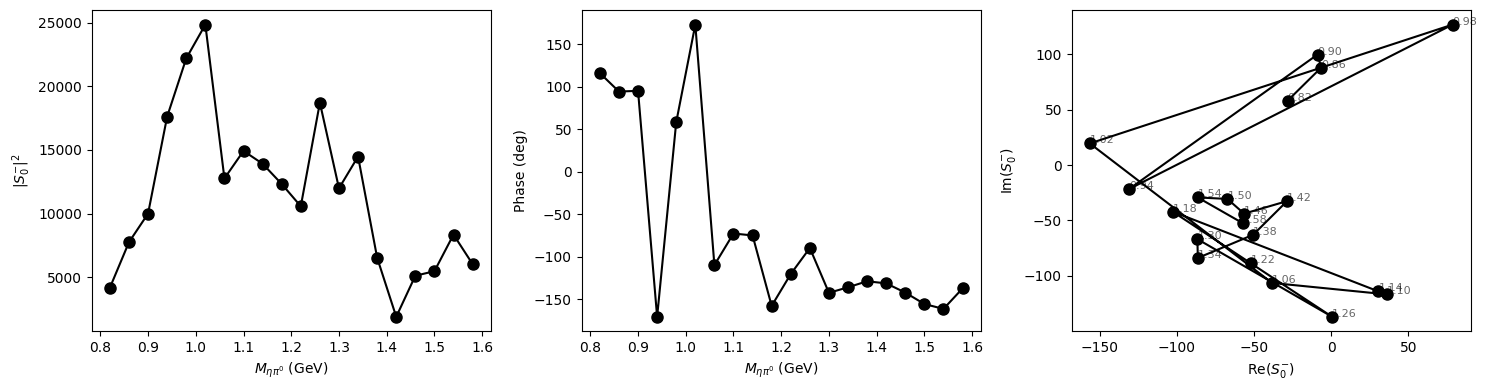

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(masses, np.abs(b_complex)**2, 'ko-', markersize=8)
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)')
ax.set_ylabel(r'$|S_0^{-}|^2$')
ax.set_title('')

ax = axes[1]
ax.plot(masses, np.angle(b_complex, deg=True), 'ko-', markersize=8)
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)')
ax.set_ylabel('Phase (deg)')
ax.set_title('')

ax = axes[2]
ax.plot(b_complex.real, b_complex.imag, 'ko-', markersize=8)
for i in range(len(masses)):
    ax.annotate(f'{masses[i]:.2f}', (b_complex.real[i], b_complex.imag[i]), 
                fontsize=8, alpha=0.6)
ax.set_xlabel(r'Re($S_0^{-}$)')
ax.set_ylabel(r'Im($S_0^{-}$)')
ax.set_title('')

plt.tight_layout()
plt.savefig(f'{out_pdf_dir}S0-_amplitudes.pdf')
plt.show()

In [16]:
# Compute conformal map for ηπ⁰ system
m_pi0 = 0.1349766  # GeV
m_eta = 0.547862   # GeV
m_threshold = m_eta + m_pi0
s_min = m_threshold**2  # ≈ 0.466 GeV²

print(f"$\eta\pi^0$ system threshold: {m_threshold:.3f} GeV (s_min = {s_min:.3f} GeV^2²)")
# Expansion point: at a₀(980) resonance
s_0 = 0.9**2
print(f"\nConformal mapping parameters:")
print(f"  s_min = {s_min:.3f} GeV² (ηπ⁰ threshold)")
print(f"  s_0   = {s_0:.3f} GeV² (a₀(980) resonance)")  
# Compute conformal variables
s_values = masses**2
z_values = conformal_map(s_values, s_min, s_0)

print(f"\nMass range: {masses.min():.3f} - {masses.max():.3f} GeV")
print(f"Conformal z range: [{z_values.min():.3f}, {z_values.max():.3f}]")
print(conformal_map(s_0, s_min, s_0))  # Should be 0

$\eta\pi^0$ system threshold: 0.683 GeV (s_min = 0.466 GeV^2²)

Conformal mapping parameters:
  s_min = 0.466 GeV² (ηπ⁰ threshold)
  s_0   = 0.810 GeV² (a₀(980) resonance)

Mass range: 0.820 - 1.580 GeV
Conformal z range: [0.166, 0.459]
0.21107231164145446


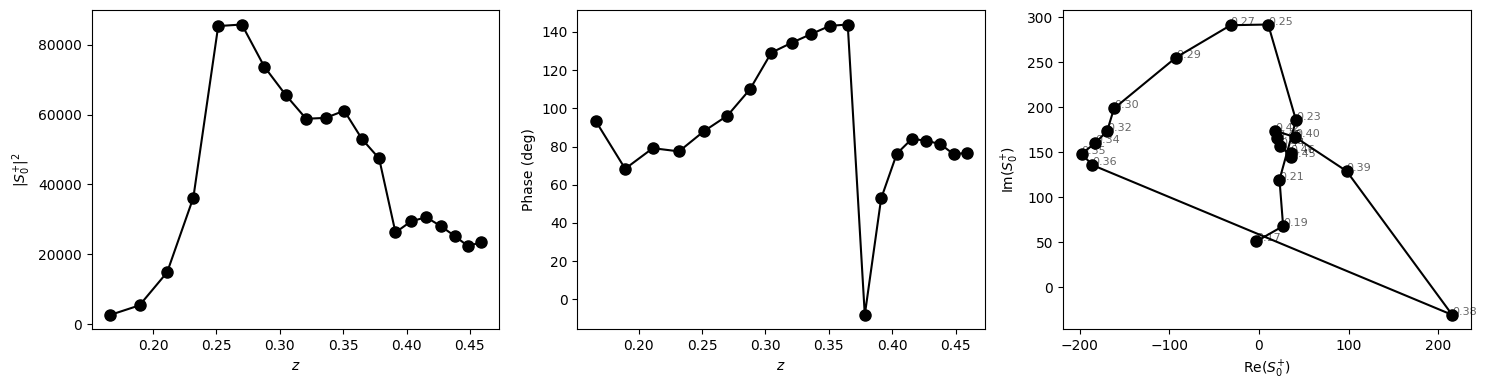

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(z_values, np.abs(a_complex)**2, 'ko-', markersize=8)
ax.set_xlabel(r'$z$')
ax.set_ylabel(r'$|S_0^{+}|^2$')
ax.set_title('')

ax = axes[1]
ax.plot(z_values, np.angle(a_complex, deg=True), 'ko-', markersize=8)
ax.set_xlabel(r'$z$')
ax.set_ylabel('Phase (deg)')
ax.set_title('')

ax = axes[2]
ax.plot(a_complex.real, a_complex.imag, 'ko-', markersize=8)
for i in range(len(z_values)):
    ax.annotate(f'{z_values[i]:.2f}', (a_complex.real[i], a_complex.imag[i]), 
                fontsize=8, alpha=0.6)
ax.set_xlabel(r'Re($S_0^{+}$)')
ax.set_ylabel(r'Im($S_0^{+}$)')
ax.set_title('')

plt.tight_layout()
# plt.savefig(f'{out_pdf_dir}S0+_amplitudes.pdf')
plt.show()

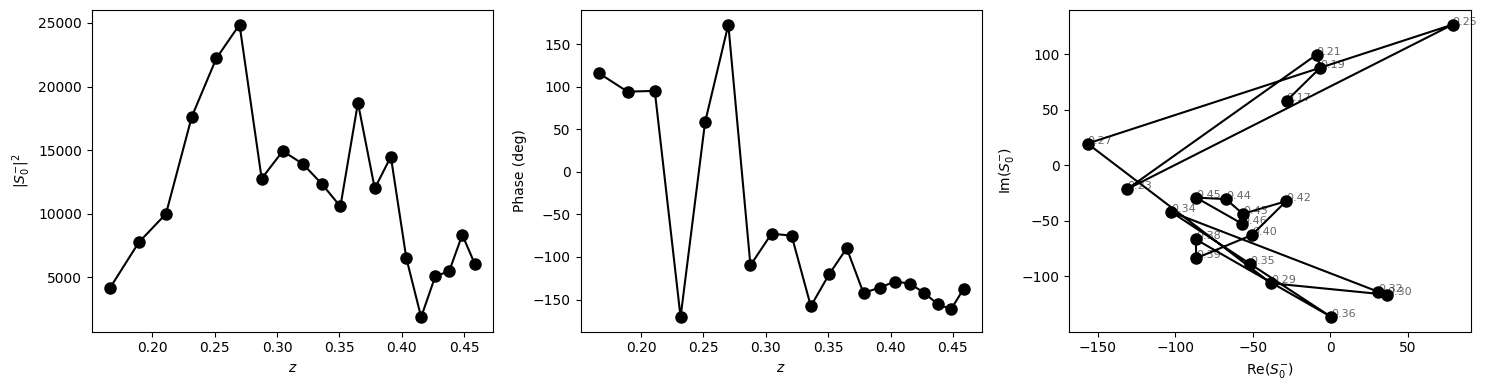

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(z_values, np.abs(b_complex)**2, 'ko-', markersize=8)
ax.set_xlabel(r'$z$')
ax.set_ylabel(r'$|S_0^{-}|^2$')
ax.set_title('')

ax = axes[1]
ax.plot(z_values, np.angle(b_complex, deg=True), 'ko-', markersize=8)
ax.set_xlabel(r'$z$')
ax.set_ylabel('Phase (deg)')
ax.set_title('')

ax = axes[2]
ax.plot(b_complex.real, b_complex.imag, 'ko-', markersize=8)
for i in range(len(z_values)):
    ax.annotate(f'{z_values[i]:.2f}', (b_complex.real[i], b_complex.imag[i]), 
                fontsize=8, alpha=0.6)
ax.set_xlabel(r'Re($S_0^{-}$)')
ax.set_ylabel(r'Im($S_0^{-}$)')
ax.set_title('')

plt.tight_layout()
# plt.savefig(f'{out_pdf_dir}S0-_amplitudes.pdf')
plt.show()

In [19]:
def chi2_conformal(params, z, data_complex):
    """
    Chi-squared function for complex conformal polynomial fit.
    
    Parameters:
    -----------
    params : array
        Real-valued parameters [a0, a1, ..., aN, b0, b1, ..., bN]
        where a_i are real parts and b_i are imaginary parts
    z : array
        Conformal variables
    data_complex : array
        Complex data to fit
    
    Returns:
    --------
    chi2 : float
        Sum of squared residuals
    """
    order = len(params) // 2 - 1
    
    # Extract real and imaginary coefficients
    a_coeffs = params[:order+1]
    b_coeffs = params[order+1:]
    
    # Build polynomial: sum (a_i + i*b_i) * z^i
    model = np.zeros_like(z, dtype=complex)
    for i in range(order + 1):
        model += (a_coeffs[i] + 1j * b_coeffs[i]) * z**i
    
    # Compute chi-squared
    residuals = data_complex - model
    chi2 = np.sum(np.abs(residuals)**2)
    
    return chi2

def chi2_conformal_magnitude(params, z, data_complex):
    """
    Fit |A|² (the physical intensity) with proper normalization.
    """
    order = len(params) // 2 - 1
    
    # Extract coefficients
    a_coeffs = params[:order+1]
    b_coeffs = params[order+1:]

    chi2 = 0.0
    
    for i in range(len(z)):
        # Build model amplitude
        model = 0
        for j in range(order + 1):
            model += (a_coeffs[j] + 1j*b_coeffs[j]) * z[i]**j
        
        # Physical observables (intensities)
        model_intensity = np.real(model * np.conj(model))
        data_intensity = np.abs(data_complex[i])**2
        
        # Relative residual (normalized by data scale)
        # This makes χ² dimensionless and O(1)
        relative_residual = (model_intensity - data_intensity) / data_intensity
        chi2 += relative_residual**2
    
    return float(chi2)


In [20]:
# Test different polynomial orders with better initial guess
print("Testing different polynomial orders for a_0_0:")
print("="*60)

orders_to_test = [1,2,3,4,5,6,7]
results = {}

# Use first data point as initial guess for constant term
a0_init_real = a_complex[4].real
a0_init_imag = a_complex[4].imag

print(f"Initial guess for a0: {a0_init_real:.2e} + i*{a0_init_imag:.2e}")

for order in orders_to_test:
    # Better initial guess: start from data scale
    n_params = 2 * (order + 1)
    initial_params = np.zeros(n_params)
    initial_params[0] = a0_init_real  # a0 ~ data scale (real)
    initial_params[order+1] = a0_init_imag  # b0 ~ data scale (imag)
    
    # Try multiple optimizers
    best_result = None
    best_chi2 = np.inf
    
    # Method 1: L-BFGS-B (gradient-based, with bounds)
    result1 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_values, a_complex),
        method='L-BFGS-B',
        options={'maxiter': 50000, 'ftol': 1e-12}
    )
    if result1.fun < best_chi2:
        best_chi2 = result1.fun
        best_result = result1
    
    # Method 2: Nelder-Mead (simplex, robust)
    result2 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_values, a_complex),
        method='Nelder-Mead',
        options={'maxiter': 50000, 'xatol': 1e-10, 'fatol': 1e-10}
    )
    if result2.fun < best_chi2:
        best_chi2 = result2.fun
        best_result = result2
    
    # Compute chi2/ndf
    ndf = len(masses) - n_params
    chi2_ndf = best_result.fun / ndf if ndf > 0 else best_result.fun
    
    results[order] = {
        'params': best_result.x,
        'chi2': best_result.fun,
        'chi2_ndf': chi2_ndf,
        'success': best_result.success
    }
    
    print(f"Order {order}: χ²/ndf = {chi2_ndf:.4f}, χ² = {best_result.fun:.2e}, ndf = {ndf}")


Testing different polynomial orders for a_0_0:
Initial guess for a0: 1.03e+01 + i*2.92e+02
Order 1: χ²/ndf = 0.4116, χ² = 6.59e+00, ndf = 16
Order 2: χ²/ndf = 0.1295, χ² = 1.81e+00, ndf = 14
Order 3: χ²/ndf = 0.0716, χ² = 8.60e-01, ndf = 12
Order 4: χ²/ndf = 0.0572, χ² = 5.72e-01, ndf = 10
Order 5: χ²/ndf = 0.0704, χ² = 5.63e-01, ndf = 8
Order 6: χ²/ndf = 0.0931, χ² = 5.59e-01, ndf = 6
Order 7: χ²/ndf = 0.1395, χ² = 5.58e-01, ndf = 4


In [21]:
# Get best fit and evaluate on fine grid
best_order = min(results.keys(), key=lambda o: results[o]['chi2_ndf'])
print(f"\nBest order: {best_order} with χ²/ndf = {results[best_order]['chi2_ndf']:.4f}")

# Evaluate fitted polynomial
best_params = results[best_order]['params']
n_coeffs = best_order + 1
a_coeffs = best_params[:n_coeffs]
b_coeffs = best_params[n_coeffs:]

# Build fitted amplitude
a_fit = np.zeros_like(z_values, dtype=complex)
for i in range(n_coeffs):
    a_fit += (a_coeffs[i] + 1j * b_coeffs[i]) * z_values**i

# Create fine grid for smooth plotting
m_fine = np.linspace(masses.min(), masses.max(), 200)
s_fine = m_fine**2
z_fine = conformal_map(s_fine, s_min, s_0)

a_fit_fine = np.zeros_like(z_fine, dtype=complex)
for i in range(n_coeffs):
    a_fit_fine += (a_coeffs[i] + 1j * b_coeffs[i]) * z_fine**i

print(f"\nFitted coefficients (order {best_order}):")
print(f"Real parts (a): {a_coeffs}")
print(f"Imag parts (b): {b_coeffs}")


Best order: 4 with χ²/ndf = 0.0572

Fitted coefficients (order 4):
Real parts (a): [ -65.10298766  684.14788675 -880.86351153  565.28701796  869.78655927]
Imag parts (b): [ -1566.96321397  13693.5371441  -28336.9265323    2928.82964619
  21936.39756629]


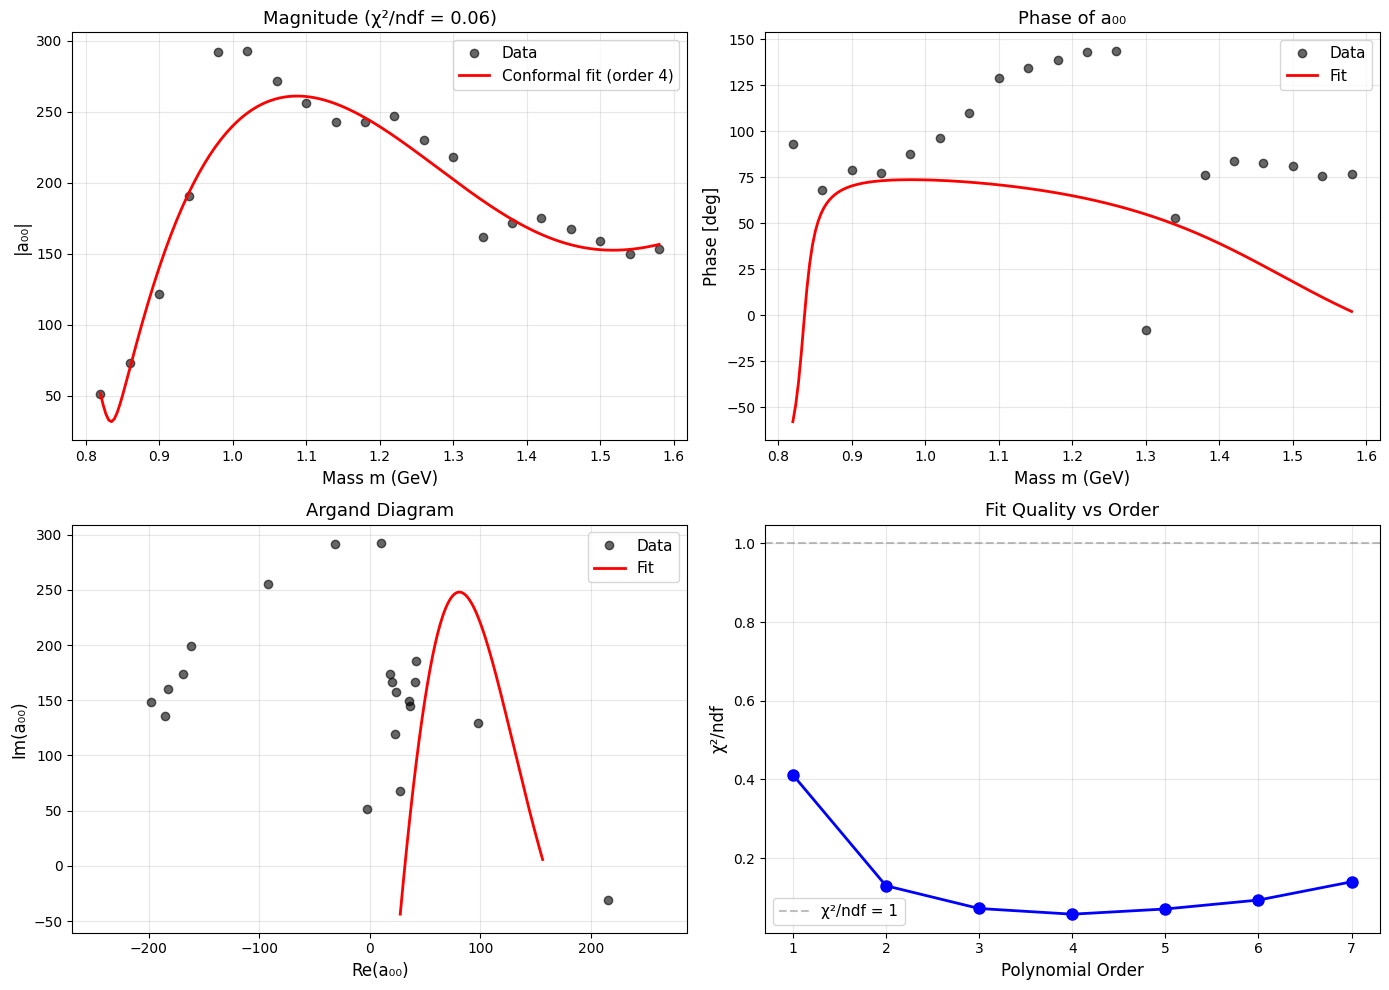


Conformal Polynomial Fit Summary
Best order: 4
χ²/ndf: 0.0572
Number of parameters: 10
Number of data points: 20


In [22]:
# Plot comprehensive comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Magnitude vs Mass
ax = axes[0, 0]
ax.plot(masses, np.abs(a_complex), 'ko', label='Data', markersize=6, alpha=0.6)
ax.plot(m_fine, np.abs(a_fit_fine), 'r-', linewidth=2, label=f'Conformal fit (order {best_order})')
ax.set_xlabel('Mass m (GeV)', fontsize=12)
ax.set_ylabel('|a₀₀|', fontsize=12)
ax.set_title(f'Magnitude (χ²/ndf = {results[best_order]["chi2_ndf"]:.2f})', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Plot 2: Phase vs Mass
ax = axes[0, 1]
ax.plot(masses, np.angle(a_complex, deg=True), 'ko', label='Data', markersize=6, alpha=0.6)
ax.plot(m_fine, np.angle(a_fit_fine, deg=True), 'r-', linewidth=2, label='Fit')
ax.set_xlabel('Mass m (GeV)', fontsize=12)
ax.set_ylabel('Phase [deg]', fontsize=12)
ax.set_title('Phase of a₀₀', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Plot 3: Argand Diagram
ax = axes[1, 0]
ax.plot(a_complex.real, a_complex.imag, 'ko', label='Data', markersize=6, alpha=0.6)
ax.plot(a_fit_fine.real, a_fit_fine.imag, 'r-', linewidth=2, label='Fit')
# Add arrows to show direction
for i in range(0, len(m_fine)-1, 20):
    dx = a_fit_fine.real[i+1] - a_fit_fine.real[i]
    dy = a_fit_fine.imag[i+1] - a_fit_fine.imag[i]
    ax.arrow(a_fit_fine.real[i], a_fit_fine.imag[i], dx, dy, 
             head_width=0.05, head_length=0.03, fc='red', ec='red', alpha=0.5)
ax.set_xlabel('Re(a₀₀)', fontsize=12)
ax.set_ylabel('Im(a₀₀)', fontsize=12)
ax.set_title('Argand Diagram', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.axis('equal')

# Plot 4: Chi2/ndf vs Order
ax = axes[1, 1]
orders = list(results.keys())
chi2_ndfs = [results[o]['chi2_ndf'] for o in orders]
ax.plot(orders, chi2_ndfs, 'o-', linewidth=2, markersize=8, color='blue')
ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='χ²/ndf = 1')
ax.set_xlabel('Polynomial Order', fontsize=12)
ax.set_ylabel('χ²/ndf', fontsize=12)
ax.set_title('Fit Quality vs Order', fontsize=13)
ax.set_xticks(orders)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('conformal_fit_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("Conformal Polynomial Fit Summary")
print("="*60)
print(f"Best order: {best_order}")
print(f"χ²/ndf: {results[best_order]['chi2_ndf']:.4f}")
print(f"Number of parameters: {2*(best_order+1)}")
print(f"Number of data points: {len(masses)}")
print("="*60)

In [23]:
# Study effect of s_0, s_min, and polynomial order on fit quality
print("Testing different s_0, s_min, and polynomial order values:")
print("="*60)

# Test range of s_0 values around a₀(980)
s_0_test_values = [0.70**2, 0.80**2, 0.90**2, 0.98**2, 1.05**2, 1.15**2]

# Test range of s_min values around physical threshold
# Physical: s_min = (m_η + m_π⁰)² = 0.466 GeV²
# Try slightly below and above to see sensitivity
s_min_test_values = [0.40**2, 0.45**2, 0.466**2, 0.48**2, 0.50**2]

# Test different polynomial orders
order_test_values = [1, 2, 3, 4, 5]

# Store results in nested dict: scan_results[order][s_min][s_0]
scan_results = {}

for order in order_test_values:
    print(f"\n{'#'*60}")
    print(f"# TESTING POLYNOMIAL ORDER = {order}")
    print(f"{'#'*60}")
    
    s_min_results = {}
    
    for s_min_test in s_min_test_values:
        print(f"\n--- s_min = {s_min_test:.4f} GeV² (m_min = {np.sqrt(s_min_test):.3f} GeV) ---")
        s_0_results = {}
        
        for s_0_test in s_0_test_values:
            # Skip if s_0 <= s_min (unphysical)
            if s_0_test <= s_min_test:
                continue
            
            # Compute conformal variables with this s_min and s_0
            z_test = conformal_map(masses**2, s_min_test, s_0_test)
            
            # Fit with current order
            n_params = 2 * (order + 1)
            initial_params = np.zeros(n_params)
            initial_params[0] = a_complex[4].real
            initial_params[order+1] = a_complex[4].imag
            
            # Try multiple optimizers to find global minimum
            best_result = None
            best_chi2 = np.inf
            
            # Method 1: L-BFGS-B
            result1 = minimize(
                chi2_conformal_magnitude,
                initial_params,
                args=(z_test, a_complex),
                method='L-BFGS-B',
                options={'maxiter': 50000, 'ftol': 1e-12}
            )
            if result1.fun < best_chi2:
                best_chi2 = result1.fun
                best_result = result1
            
            # Method 2: Nelder-Mead for robustness
            result2 = minimize(
                chi2_conformal_magnitude,
                initial_params,
                args=(z_test, a_complex),
                method='Nelder-Mead',
                options={'maxiter': 50000, 'xatol': 1e-10, 'fatol': 1e-10}
            )
            if result2.fun < best_chi2:
                best_chi2 = result2.fun
                best_result = result2
            
            ndf = len(masses) - n_params
            chi2_ndf = best_result.fun / ndf
            
            s_0_results[s_0_test] = {
                'params': best_result.x,
                'chi2_ndf': chi2_ndf,
                'chi2': best_result.fun,
                'z_values': z_test,
                'm_0': np.sqrt(s_0_test),
                'ndf': ndf
            }
            
            print(f"  s_0 = {s_0_test:.3f} GeV² (√s_0 = {np.sqrt(s_0_test):.3f} GeV): χ²/ndf = {chi2_ndf:.4f}")
        
        s_min_results[s_min_test] = s_0_results
    
    scan_results[order] = s_min_results

# Find best (order, s_min, s_0) combination
best_chi2_ndf = np.inf
best_order = None
best_s_min = None
best_s_0 = None

for order, s_min_dict in scan_results.items():
    for s_min_test, s_0_dict in s_min_dict.items():
        for s_0_test, result in s_0_dict.items():
            if result['chi2_ndf'] < best_chi2_ndf:
                best_chi2_ndf = result['chi2_ndf']
                best_order = order
                best_s_min = s_min_test
                best_s_0 = s_0_test

print(f"\n{'='*60}")
print(f"BEST COMBINATION:")
print(f"  Order = {best_order}")
print(f"  s_min = {best_s_min:.4f} GeV² (√s_min = {np.sqrt(best_s_min):.3f} GeV)")
print(f"  s_0   = {best_s_0:.4f} GeV² (√s_0 = {np.sqrt(best_s_0):.3f} GeV)")
print(f"  χ²/ndf = {best_chi2_ndf:.4f}")
print(f"  n_params = {2*(best_order+1)}")
print(f"={'='*60}")


Testing different s_0, s_min, and polynomial order values:

############################################################
# TESTING POLYNOMIAL ORDER = 1
############################################################

--- s_min = 0.1600 GeV² (m_min = 0.400 GeV) ---
  s_0 = 0.490 GeV² (√s_0 = 0.700 GeV): χ²/ndf = 0.4112
  s_0 = 0.640 GeV² (√s_0 = 0.800 GeV): χ²/ndf = 0.4144
  s_0 = 0.810 GeV² (√s_0 = 0.900 GeV): χ²/ndf = 0.4171
  s_0 = 0.960 GeV² (√s_0 = 0.980 GeV): χ²/ndf = 0.4190
  s_0 = 1.103 GeV² (√s_0 = 1.050 GeV): χ²/ndf = 0.4205
  s_0 = 1.322 GeV² (√s_0 = 1.150 GeV): χ²/ndf = 0.4224

--- s_min = 0.2025 GeV² (m_min = 0.450 GeV) ---
  s_0 = 0.490 GeV² (√s_0 = 0.700 GeV): χ²/ndf = 0.4101
  s_0 = 0.640 GeV² (√s_0 = 0.800 GeV): χ²/ndf = 0.4136
  s_0 = 0.810 GeV² (√s_0 = 0.900 GeV): χ²/ndf = 0.4165
  s_0 = 0.960 GeV² (√s_0 = 0.980 GeV): χ²/ndf = 0.4185
  s_0 = 1.103 GeV² (√s_0 = 1.050 GeV): χ²/ndf = 0.4201
  s_0 = 1.322 GeV² (√s_0 = 1.150 GeV): χ²/ndf = 0.4221

--- s_min = 0.2172 GeV² (m_m

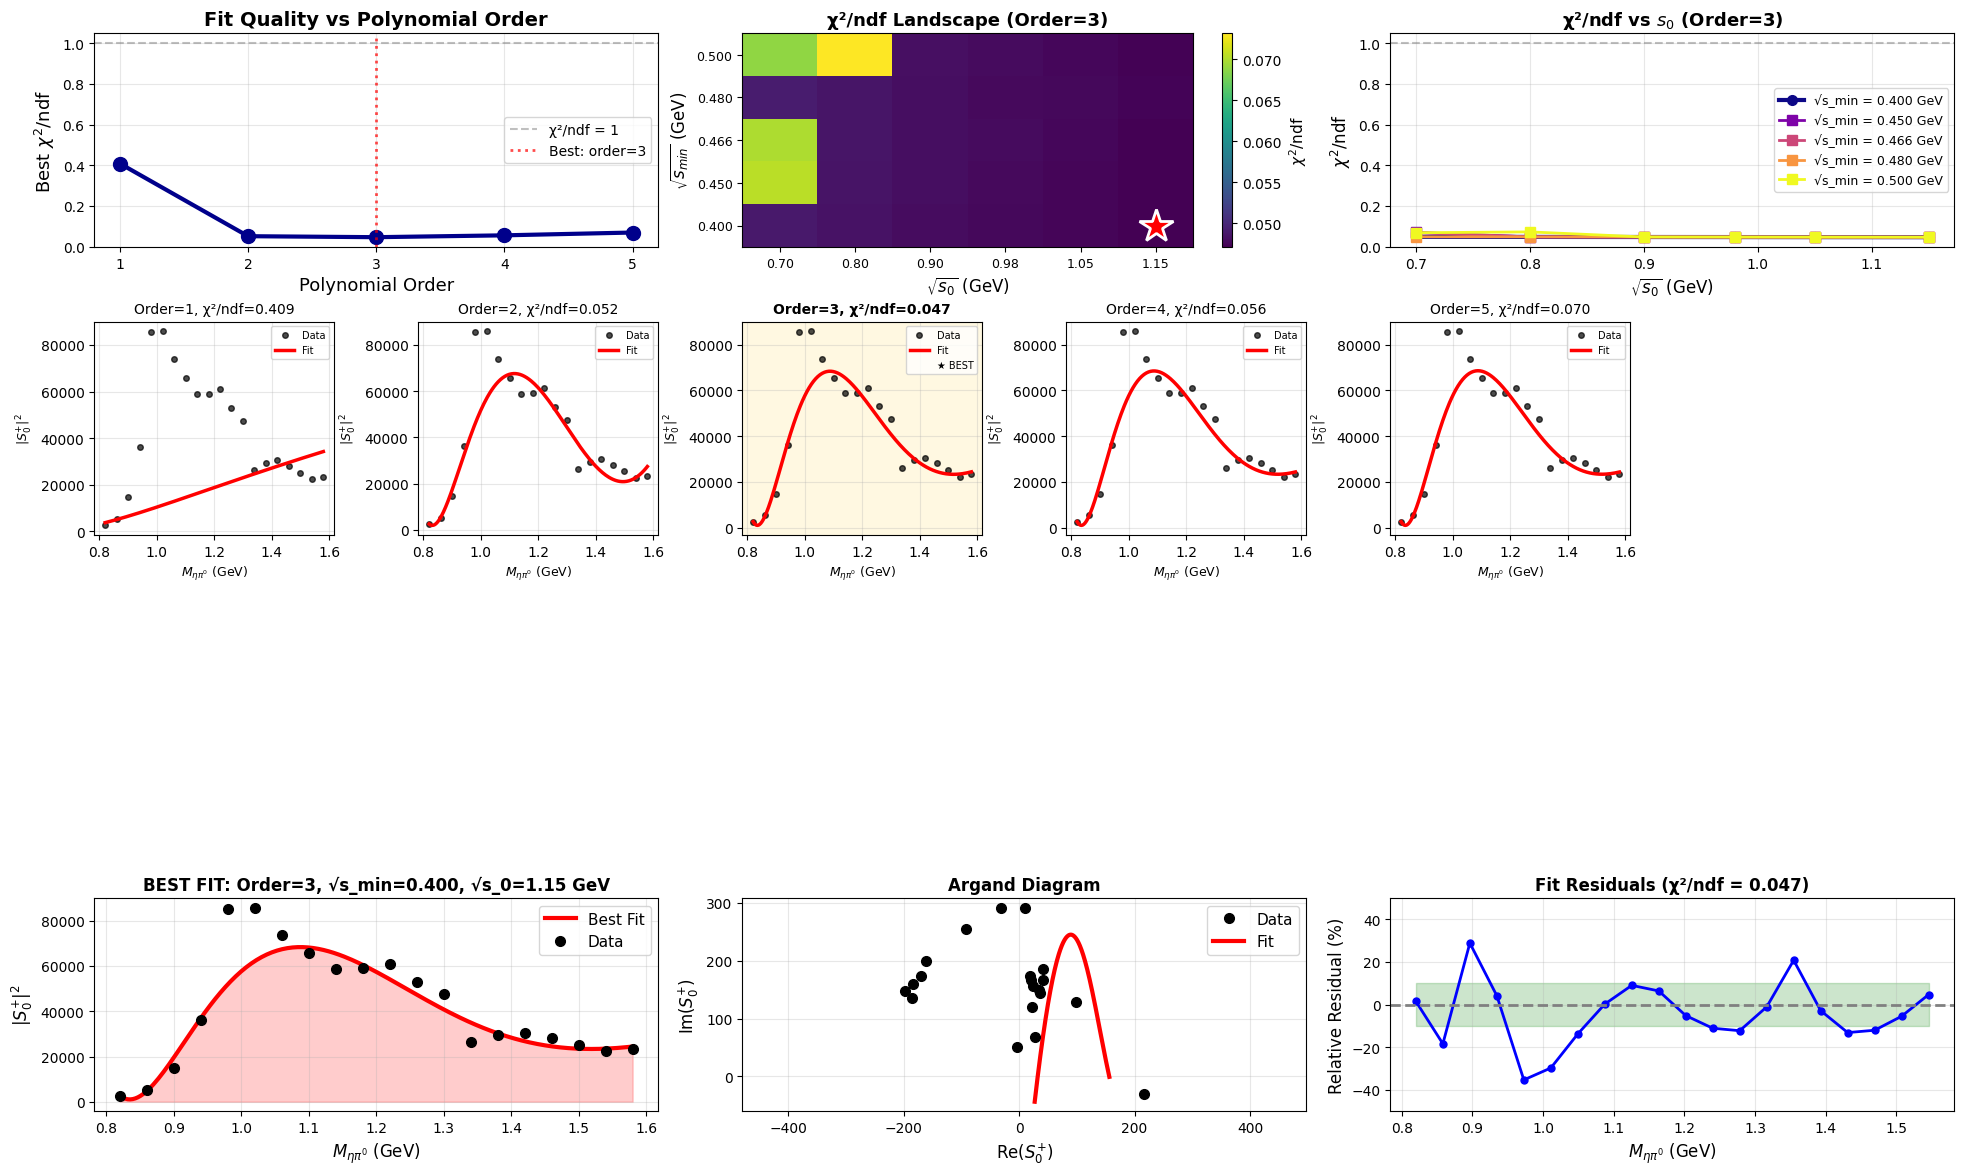


Summary: Full Parameter Scan Results

────────────────────────────────────────────────────────────
POLYNOMIAL ORDER = 1
────────────────────────────────────────────────────────────

  s_min = 0.1600 GeV² (√s_min = 0.400 GeV):
    s_0 = 0.490 GeV² (√s_0 = 0.700 GeV): χ²/ndf = 0.4112
    s_0 = 0.640 GeV² (√s_0 = 0.800 GeV): χ²/ndf = 0.4144
    s_0 = 0.810 GeV² (√s_0 = 0.900 GeV): χ²/ndf = 0.4171
    s_0 = 0.960 GeV² (√s_0 = 0.980 GeV): χ²/ndf = 0.4190
    s_0 = 1.103 GeV² (√s_0 = 1.050 GeV): χ²/ndf = 0.4205
    s_0 = 1.322 GeV² (√s_0 = 1.150 GeV): χ²/ndf = 0.4224

  s_min = 0.2025 GeV² (√s_min = 0.450 GeV):
    s_0 = 0.490 GeV² (√s_0 = 0.700 GeV): χ²/ndf = 0.4101
    s_0 = 0.640 GeV² (√s_0 = 0.800 GeV): χ²/ndf = 0.4136
    s_0 = 0.810 GeV² (√s_0 = 0.900 GeV): χ²/ndf = 0.4165
    s_0 = 0.960 GeV² (√s_0 = 0.980 GeV): χ²/ndf = 0.4185
    s_0 = 1.103 GeV² (√s_0 = 1.050 GeV): χ²/ndf = 0.4201
    s_0 = 1.322 GeV² (√s_0 = 1.150 GeV): χ²/ndf = 0.4221

  s_min = 0.2172 GeV² (√s_min = 0.466 GeV):

In [24]:
# Create comprehensive visualization of results
fig = plt.figure(figsize=(24, 14))
gs = fig.add_gridspec(4, 6, hspace=0.35, wspace=0.35)

# Plot 1: χ²/ndf vs polynomial order (for best s_min, s_0 at each order)
ax_order = fig.add_subplot(gs[0, :2])
order_list = []
chi2_list = []
for order in order_test_values:
    # Find best chi2 for this order
    best_chi2_for_order = np.inf
    for s_min_test, s_0_dict in scan_results[order].items():
        for s_0_test, result in s_0_dict.items():
            if result['chi2_ndf'] < best_chi2_for_order:
                best_chi2_for_order = result['chi2_ndf']
    order_list.append(order)
    chi2_list.append(best_chi2_for_order)

ax_order.plot(order_list, chi2_list, 'o-', linewidth=3, markersize=10, color='darkblue')
ax_order.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='χ²/ndf = 1')
ax_order.axvline(best_order, color='red', linestyle=':', alpha=0.7, linewidth=2, label=f'Best: order={best_order}')
ax_order.set_xlabel('Polynomial Order', fontsize=13)
ax_order.set_ylabel(r'Best $\chi^2$/ndf', fontsize=13)
ax_order.set_title('Fit Quality vs Polynomial Order', fontsize=14, fontweight='bold')
ax_order.set_xticks(order_test_values)
ax_order.legend(fontsize=10)
ax_order.grid(True, alpha=0.3)

# Plot 2: Heatmap of χ²/ndf vs (s_min, s_0) for best order
ax_heat = fig.add_subplot(gs[0, 2:4])

s_min_results_best = scan_results[best_order]
chi2_grid = np.full((len(s_min_test_values), len(s_0_test_values)), np.nan)
for i, s_min_test in enumerate(s_min_test_values):
    for j, s_0_test in enumerate(s_0_test_values):
        if s_min_test in s_min_results_best and s_0_test in s_min_results_best[s_min_test]:
            chi2_grid[i, j] = s_min_results_best[s_min_test][s_0_test]['chi2_ndf']

im = ax_heat.imshow(chi2_grid, aspect='auto', origin='lower', cmap='viridis')
ax_heat.set_xticks(range(len(s_0_test_values)))
ax_heat.set_xticklabels([f'{np.sqrt(s):.2f}' for s in s_0_test_values], fontsize=9)
ax_heat.set_yticks(range(len(s_min_test_values)))
ax_heat.set_yticklabels([f'{np.sqrt(s):.3f}' for s in s_min_test_values], fontsize=9)
ax_heat.set_xlabel(r'$\sqrt{s_0}$ (GeV)', fontsize=12)
ax_heat.set_ylabel(r'$\sqrt{s_{min}}$ (GeV)', fontsize=12)
ax_heat.set_title(f'χ²/ndf Landscape (Order={best_order})', fontsize=13, fontweight='bold')

# Mark best point
best_i = list(s_min_test_values).index(best_s_min)
best_j = list(s_0_test_values).index(best_s_0)
ax_heat.plot(best_j, best_i, 'r*', markersize=25, markeredgecolor='white', markeredgewidth=2)

cbar = plt.colorbar(im, ax=ax_heat)
cbar.set_label(r'$\chi^2$/ndf', fontsize=11)

# Plot 3: χ²/ndf vs s_0 for each s_min (best order)
ax_s0 = fig.add_subplot(gs[0, 4:])
colors = plt.cm.plasma(np.linspace(0, 1, len(s_min_test_values)))

for idx, s_min_test in enumerate(s_min_test_values):
    if s_min_test not in s_min_results_best:
        continue
    s_0_list = []
    chi2_list = []
    for s_0_test in s_0_test_values:
        if s_0_test in s_min_results_best[s_min_test]:
            s_0_list.append(np.sqrt(s_0_test))
            chi2_list.append(s_min_results_best[s_min_test][s_0_test]['chi2_ndf'])
    
    if s_0_list:
        marker = 'o' if s_min_test == best_s_min else 's'
        lw = 3 if s_min_test == best_s_min else 2
        ax_s0.plot(s_0_list, chi2_list, marker=marker, linestyle='-', linewidth=lw, markersize=7, 
                   color=colors[idx], label=f'√s_min = {np.sqrt(s_min_test):.3f} GeV')

ax_s0.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
ax_s0.set_xlabel(r'$\sqrt{s_0}$ (GeV)', fontsize=12)
ax_s0.set_ylabel(r'$\chi^2$/ndf', fontsize=12)
ax_s0.set_title(f'χ²/ndf vs $s_0$ (Order={best_order})', fontsize=13, fontweight='bold')
ax_s0.legend(fontsize=9, loc='best')
ax_s0.grid(True, alpha=0.3)

# Plots 4-8: Show best fit overlays for different orders
for idx, order in enumerate(order_test_values):
    row = 1 + idx // 6
    col = idx % 6
    ax = fig.add_subplot(gs[row, col])
    
    # Find best (s_min, s_0) for this order
    best_chi2_for_order = np.inf
    best_s_min_for_order = None
    best_s_0_for_order = None
    
    for s_min_test, s_0_dict in scan_results[order].items():
        for s_0_test, result in s_0_dict.items():
            if result['chi2_ndf'] < best_chi2_for_order:
                best_chi2_for_order = result['chi2_ndf']
                best_s_min_for_order = s_min_test
                best_s_0_for_order = s_0_test
    
    if best_s_0_for_order is None:
        continue
    
    # Get fit parameters
    fit_params = scan_results[order][best_s_min_for_order][best_s_0_for_order]['params']
    n_coeffs = order + 1
    a_coeffs = fit_params[:n_coeffs]
    b_coeffs = fit_params[n_coeffs:]
    
    # Evaluate fitted polynomial on fine grid
    m_fine = np.linspace(masses.min(), masses.max(), 200)
    s_fine = m_fine**2
    z_fine = conformal_map(s_fine, best_s_min_for_order, best_s_0_for_order)
    
    a_fit_fine = np.zeros_like(z_fine, dtype=complex)
    for i in range(n_coeffs):
        a_fit_fine += (a_coeffs[i] + 1j * b_coeffs[i]) * z_fine**i
    
    # Plot data and fit for |A|²
    ax.plot(masses, np.abs(a_complex)**2, 'ko', label='Data', markersize=4, alpha=0.7)
    ax.plot(m_fine, np.abs(a_fit_fine)**2, 'r-', linewidth=2.5, label='Fit')
    
    is_best = (order == best_order)
    if is_best:
        ax.set_facecolor('#fff8e1')
        ax.plot([], [], ' ', label='★ BEST')
    
    ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=9)
    ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=9)
    title_str = f'Order={order}, χ²/ndf={best_chi2_for_order:.3f}'
    ax.set_title(title_str, fontsize=10, fontweight='bold' if is_best else 'normal')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, alpha=0.3)

# Plot bottom row: Show best fit with different representations
row = 3

# Best fit: |A|²
ax = fig.add_subplot(gs[row, 0:2])
fit_params = scan_results[best_order][best_s_min][best_s_0]['params']
n_coeffs = best_order + 1
a_coeffs = fit_params[:n_coeffs]
b_coeffs = fit_params[n_coeffs:]

m_fine = np.linspace(masses.min(), masses.max(), 200)
s_fine = m_fine**2
z_fine = conformal_map(s_fine, best_s_min, best_s_0)

a_fit_fine = np.zeros_like(z_fine, dtype=complex)
for i in range(n_coeffs):
    a_fit_fine += (a_coeffs[i] + 1j * b_coeffs[i]) * z_fine**i

ax.errorbar(masses, np.abs(a_complex)**2, fmt='ko', markersize=7, capsize=3, label='Data')
ax.plot(m_fine, np.abs(a_fit_fine)**2, 'r-', linewidth=3, label='Best Fit')
ax.fill_between(m_fine, 0, np.abs(a_fit_fine)**2, alpha=0.2, color='red')
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=12)
ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=12)
ax.set_title(f'BEST FIT: Order={best_order}, √s_min={np.sqrt(best_s_min):.3f}, √s_0={np.sqrt(best_s_0):.2f} GeV', 
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

# Best fit: Argand diagram
ax = fig.add_subplot(gs[row, 2:4])
ax.plot(a_complex.real, a_complex.imag, 'ko', markersize=7, label='Data', zorder=3)
ax.plot(a_fit_fine.real, a_fit_fine.imag, 'r-', linewidth=3, label='Fit', zorder=2)
for i in range(0, len(m_fine)-1, 15):
    dx = a_fit_fine.real[i+1] - a_fit_fine.real[i]
    dy = a_fit_fine.imag[i+1] - a_fit_fine.imag[i]
    ax.arrow(a_fit_fine.real[i], a_fit_fine.imag[i], dx, dy, 
             head_width=0.03, head_length=0.02, fc='red', ec='red', alpha=0.6, zorder=1)
ax.set_xlabel(r'Re($S_0^{+}$)', fontsize=12)
ax.set_ylabel(r'Im($S_0^{+}$)', fontsize=12)
ax.set_title('Argand Diagram', fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.axis('equal')

# Residuals plot
ax = fig.add_subplot(gs[row, 4:])
residuals = (np.abs(a_fit_fine[::10])**2 - np.interp(m_fine[::10], masses, np.abs(a_complex)**2)) / np.interp(m_fine[::10], masses, np.abs(a_complex)**2)
ax.plot(m_fine[::10], residuals * 100, 'bo-', markersize=5, linewidth=2)
ax.axhline(0, color='gray', linestyle='--', linewidth=2)
ax.fill_between(m_fine[::10], -10, 10, alpha=0.2, color='green')
ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=12)
ax.set_ylabel('Relative Residual (%)', fontsize=12)
ax.set_title(f'Fit Residuals (χ²/ndf = {best_chi2_ndf:.3f})', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_ylim(-50, 50)

plt.savefig(f'{out_pdf_dir}parameter_scan_comprehensive.pdf', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("Summary: Full Parameter Scan Results")
print("="*60)
for order in order_test_values:
    print(f"\n{'─'*60}")
    print(f"POLYNOMIAL ORDER = {order}")
    print(f"{'─'*60}")
    for s_min_test in s_min_test_values:
        if s_min_test not in scan_results[order] or not scan_results[order][s_min_test]:
            continue
        print(f"\n  s_min = {s_min_test:.4f} GeV² (√s_min = {np.sqrt(s_min_test):.3f} GeV):")
        for s_0_test in s_0_test_values:
            if s_0_test in scan_results[order][s_min_test]:
                chi2_ndf = scan_results[order][s_min_test][s_0_test]['chi2_ndf']
                marker = " ✓✓✓ GLOBAL BEST" if (order == best_order and s_min_test == best_s_min and s_0_test == best_s_0) else ""
                print(f"    s_0 = {s_0_test:.3f} GeV² (√s_0 = {np.sqrt(s_0_test):.3f} GeV): χ²/ndf = {chi2_ndf:.4f}{marker}")
print("="*60)


In [25]:
# Presentation-quality plots: S_0^+ (a_0_0) magnitude fits with polynomial order variation
# Use physical threshold parameters: s_min = (m_η + m_π⁰)² and s_0 = 0.98² (near a_0(980))

import matplotlib.pyplot as plt
import numpy as np

# Set publication-quality plot parameters
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['ytick.major.size'] = 6

# Physical parameters
s_min_phys = m_threshold**2  # 0.466 GeV²
s_0_phys = 0.98**2  # Near a₀(980) resonance

# Fit different polynomial orders with physical parameters
print("Fitting S₀⁺ amplitude with physical parameters:")
print(f"s_min = {s_min_phys:.4f} GeV² (ηπ⁰ threshold)")
print(f"s_0 = {s_0_phys:.4f} GeV² (near a₀(980))")
print("="*70)

z_phys = conformal_map(masses**2, s_min_phys, s_0_phys)

orders_presentation = [1, 2, 3, 4, 5]
fits_a = {}

for order in orders_presentation:
    n_params = 2 * (order + 1)
    initial_params = np.zeros(n_params)
    initial_params[0] = a_complex[4].real
    initial_params[order+1] = a_complex[4].imag
    
    # Use both optimizers
    best_result = None
    best_chi2 = np.inf
    
    result1 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_phys, a_complex),
        method='L-BFGS-B',
        options={'maxiter': 50000, 'ftol': 1e-12}
    )
    if result1.fun < best_chi2:
        best_chi2 = result1.fun
        best_result = result1
    
    result2 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_phys, a_complex),
        method='Nelder-Mead',
        options={'maxiter': 50000, 'xatol': 1e-10, 'fatol': 1e-10}
    )
    if result2.fun < best_chi2:
        best_chi2 = result2.fun
        best_result = result2
    
    ndf = len(masses) - n_params
    chi2_ndf = best_result.fun / ndf
    
    # Store results
    n_coeffs = order + 1
    a_coeffs = best_result.x[:n_coeffs]
    b_coeffs = best_result.x[n_coeffs:]
    
    # Evaluate on fine grid
    m_fine = np.linspace(masses.min(), masses.max(), 300)
    s_fine = m_fine**2
    z_fine = conformal_map(s_fine, s_min_phys, s_0_phys)
    
    a_fit_fine = np.zeros_like(z_fine, dtype=complex)
    for i in range(n_coeffs):
        a_fit_fine += (a_coeffs[i] + 1j * b_coeffs[i]) * z_fine**i
    
    fits_a[order] = {
        'chi2_ndf': chi2_ndf,
        'chi2': best_result.fun,
        'ndf': ndf,
        'params': best_result.x,
        'm_fine': m_fine,
        'fit_fine': a_fit_fine
    }
    
    print(f"Order {order}: χ²/ndf = {chi2_ndf:.4f} (χ² = {best_result.fun:.2f}, ndf = {ndf})")

print("="*70)


Fitting S₀⁺ amplitude with physical parameters:
s_min = 0.4663 GeV² (ηπ⁰ threshold)
s_0 = 0.9604 GeV² (near a₀(980))
Order 1: χ²/ndf = 0.4147 (χ² = 6.63, ndf = 16)
Order 2: χ²/ndf = 0.0564 (χ² = 0.79, ndf = 14)
Order 3: χ²/ndf = 0.0484 (χ² = 0.58, ndf = 12)
Order 4: χ²/ndf = 0.0566 (χ² = 0.57, ndf = 10)
Order 5: χ²/ndf = 0.0700 (χ² = 0.56, ndf = 8)


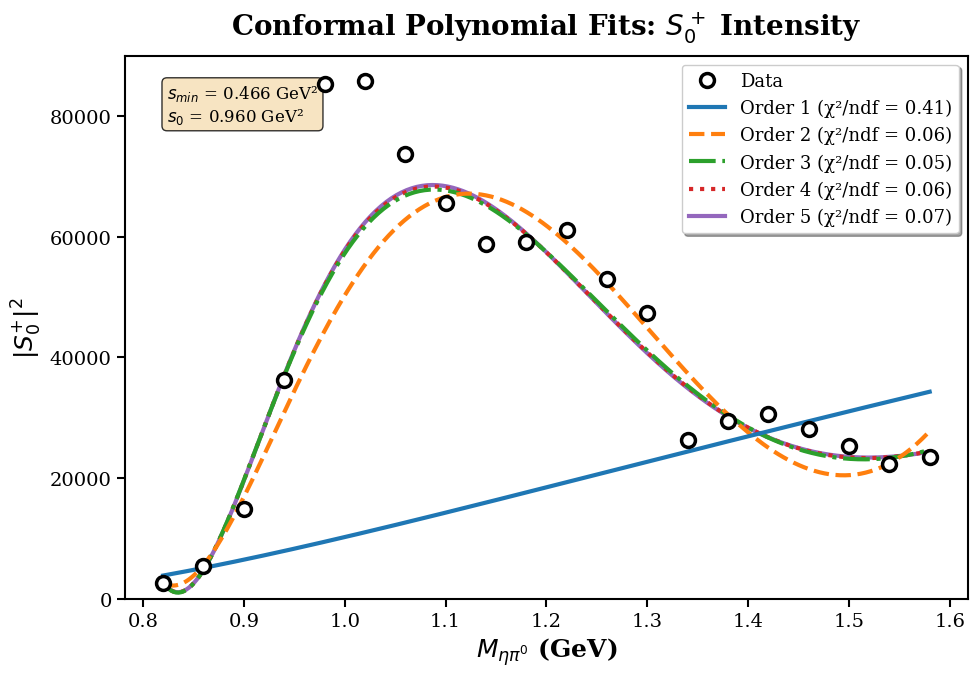

Saved: /d/home/septian/EtaPi0Plot/S0plus_polynomial_comparison.pdf
Saved: /d/home/septian/EtaPi0Plot/S0plus_polynomial_comparison.png


In [26]:
# Presentation plot 1: S_0^+ magnitude fits - Single panel with all orders
fig, ax = plt.subplots(figsize=(10, 7))

# Plot data with error bars (if available, otherwise just markers)
ax.plot(masses, np.abs(a_complex)**2, 'o', color='black', markersize=10, 
        markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)

# Colors for different orders
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
linestyles = ['-', '--', '-.', ':', '-']

# Plot fits for each order
for idx, order in enumerate(orders_presentation):
    m_fine = fits_a[order]['m_fine']
    fit_fine = fits_a[order]['fit_fine']
    chi2_ndf = fits_a[order]['chi2_ndf']
    
    ax.plot(m_fine, np.abs(fit_fine)**2, 
            linestyle=linestyles[idx], linewidth=3, color=colors[idx],
            label=f'Order {order} (χ²/ndf = {chi2_ndf:.2f})', zorder=5-idx)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=18, fontweight='bold')
ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=18, fontweight='bold')
ax.set_title(r'Conformal Polynomial Fits: $S_0^+$ Intensity', fontsize=20, fontweight='bold', pad=15)

ax.legend(fontsize=13, loc='upper right', frameon=True, shadow=True, fancybox=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

# Add text box with fit parameters
textstr = f'$s_{{min}}$ = {s_min_phys:.3f} GeV²\n$s_0$ = {s_0_phys:.3f} GeV²'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.savefig(f'{out_pdf_dir}S0plus_polynomial_comparison.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}S0plus_polynomial_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}S0plus_polynomial_comparison.pdf")
print(f"Saved: {out_pdf_dir}S0plus_polynomial_comparison.png")


/tmp/ipykernel_1050940/4021294926.py:51: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.tight_layout(rect=[0, 0, 1, 0.98])
/tmp/ipykernel_1050940/4021294926.py:52: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0plus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1050940/4021294926.py:52: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0plus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1050940/4021294926.py:53: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0plus_polynomial_multipanel.png', dpi=300, bbox_inches='tight')
/d/home/septian/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


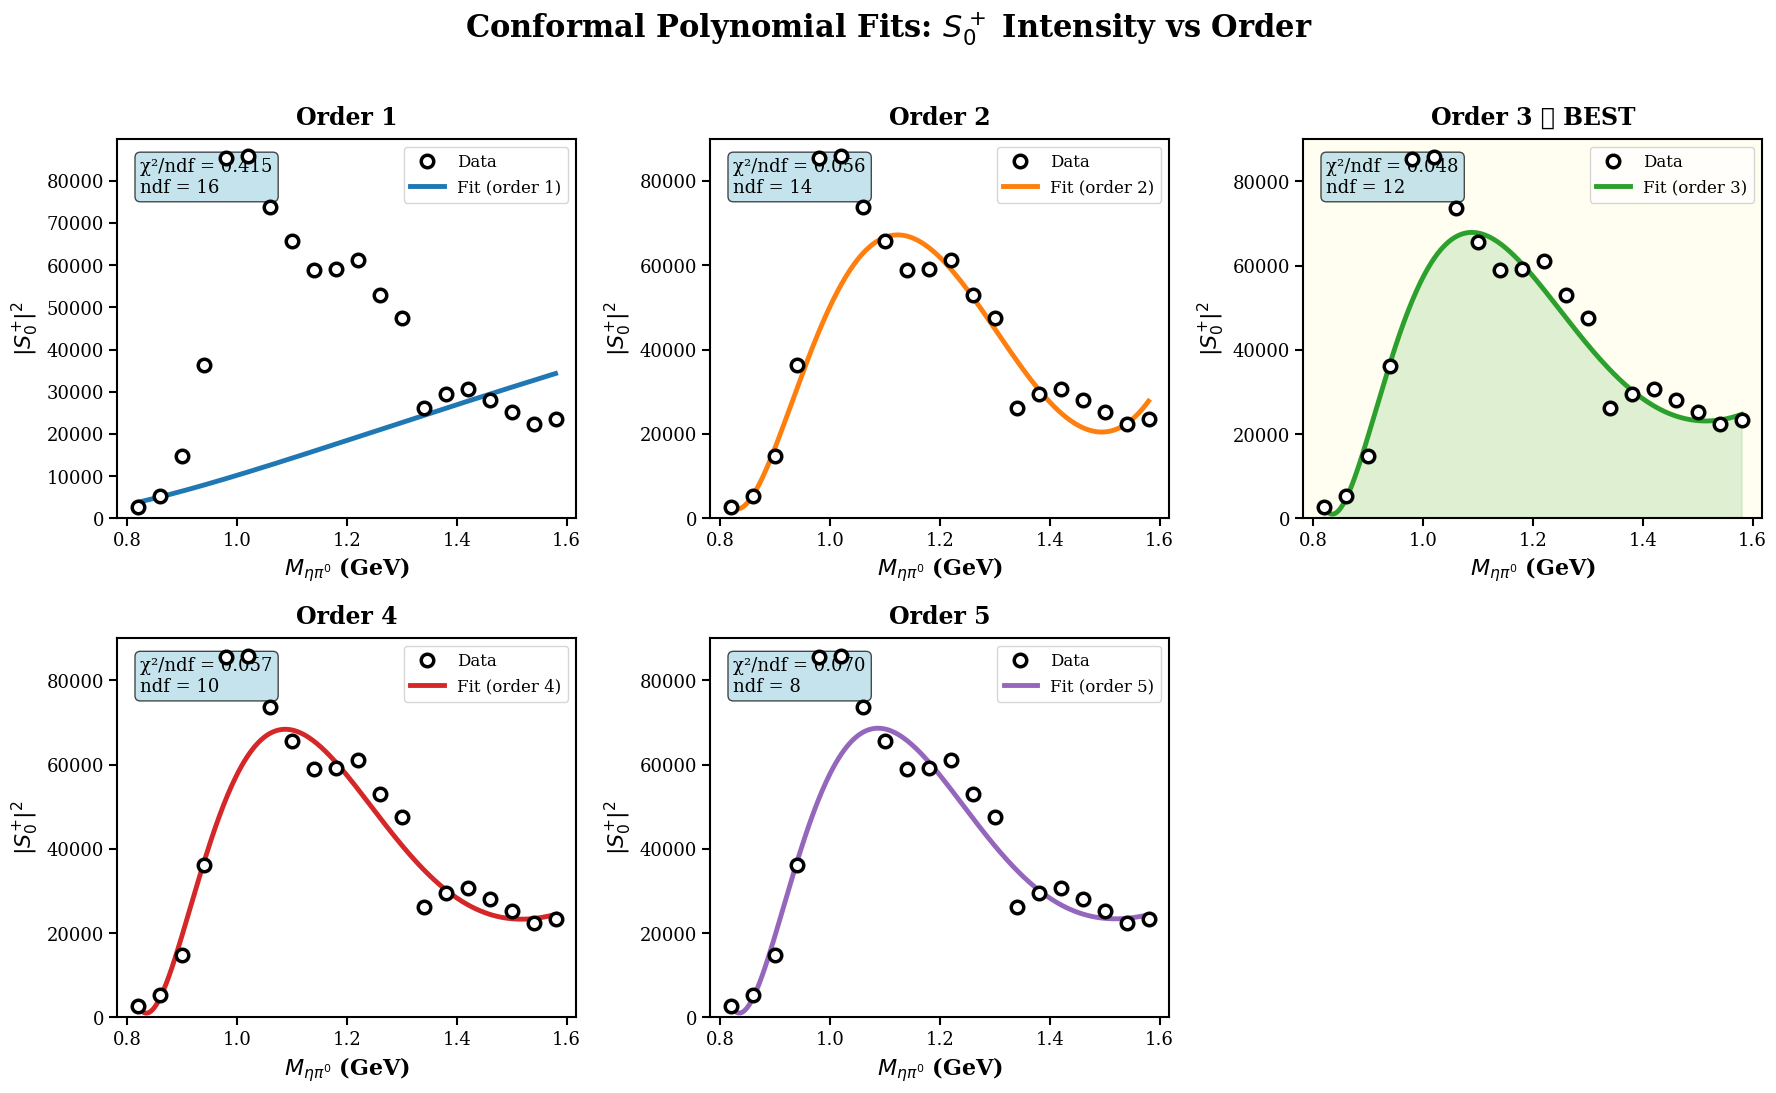

Saved: /d/home/septian/EtaPi0Plot/S0plus_polynomial_multipanel.pdf
Saved: /d/home/septian/EtaPi0Plot/S0plus_polynomial_multipanel.png


In [27]:
# Presentation plot 2: Multi-panel comparison (2x3 grid)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, order in enumerate(orders_presentation):
    ax = axes[idx]
    m_fine = fits_a[order]['m_fine']
    fit_fine = fits_a[order]['fit_fine']
    chi2_ndf = fits_a[order]['chi2_ndf']
    ndf = fits_a[order]['ndf']
    
    # Plot data
    ax.plot(masses, np.abs(a_complex)**2, 'o', color='black', markersize=9, 
            markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)
    
    # Plot fit
    ax.plot(m_fine, np.abs(fit_fine)**2, '-', linewidth=3.5, color=colors[idx],
            label=f'Fit (order {order})', zorder=5)
    
    # Fill under curve for best fit
    if order == 3:
        ax.fill_between(m_fine, 0, np.abs(fit_fine)**2, alpha=0.15, color=colors[idx])
        ax.set_facecolor('#fffef0')  # Subtle highlight
    
    ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=16, fontweight='bold')
    ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=16, fontweight='bold')
    
    title_text = f'Order {order}'
    if order == 3:
        title_text += ' ★ BEST'
    ax.set_title(title_text, fontsize=17, fontweight='bold', pad=10)
    
    # Add chi2 info
    textstr = f'χ²/ndf = {chi2_ndf:.3f}\nndf = {ndf}'
    props = dict(boxstyle='round', facecolor='lightblue', alpha=0.7)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=13,
            verticalalignment='top', bbox=props)
    
    ax.legend(fontsize=12, loc='upper right', frameon=True)
    ax.grid(False)
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=13)

# Remove the 6th empty subplot
fig.delaxes(axes[5])

# Add overall title
fig.suptitle(r'Conformal Polynomial Fits: $S_0^+$ Intensity vs Order', 
             fontsize=22, fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(f'{out_pdf_dir}S0plus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}S0plus_polynomial_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}S0plus_polynomial_multipanel.pdf")
print(f"Saved: {out_pdf_dir}S0plus_polynomial_multipanel.png")


In [28]:
# Fit S_0^- (b_0_0) amplitude with same physical parameters
print("\nFitting S₀⁻ amplitude with physical parameters:")
print(f"s_min = {s_min_phys:.4f} GeV² (ηπ⁰ threshold)")
print(f"s_0 = {s_0_phys:.4f} GeV² (near a₀(980))")
print("="*70)

fits_b = {}

for order in orders_presentation:
    n_params = 2 * (order + 1)
    initial_params = np.zeros(n_params)
    initial_params[0] = b_complex[4].real
    initial_params[order+1] = b_complex[4].imag
    
    # Use both optimizers
    best_result = None
    best_chi2 = np.inf
    
    result1 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_phys, b_complex),
        method='L-BFGS-B',
        options={'maxiter': 50000, 'ftol': 1e-12}
    )
    if result1.fun < best_chi2:
        best_chi2 = result1.fun
        best_result = result1
    
    result2 = minimize(
        chi2_conformal_magnitude,
        initial_params,
        args=(z_phys, b_complex),
        method='Nelder-Mead',
        options={'maxiter': 50000, 'xatol': 1e-10, 'fatol': 1e-10}
    )
    if result2.fun < best_chi2:
        best_chi2 = result2.fun
        best_result = result2
    
    ndf = len(masses) - n_params
    chi2_ndf = best_result.fun / ndf
    
    # Store results
    n_coeffs = order + 1
    a_coeffs = best_result.x[:n_coeffs]
    b_coeffs = best_result.x[n_coeffs:]
    
    # Evaluate on fine grid
    m_fine = np.linspace(masses.min(), masses.max(), 300)
    s_fine = m_fine**2
    z_fine = conformal_map(s_fine, s_min_phys, s_0_phys)
    
    b_fit_fine = np.zeros_like(z_fine, dtype=complex)
    for i in range(n_coeffs):
        b_fit_fine += (a_coeffs[i] + 1j * b_coeffs[i]) * z_fine**i
    
    fits_b[order] = {
        'chi2_ndf': chi2_ndf,
        'chi2': best_result.fun,
        'ndf': ndf,
        'params': best_result.x,
        'm_fine': m_fine,
        'fit_fine': b_fit_fine
    }
    
    print(f"Order {order}: χ²/ndf = {chi2_ndf:.4f} (χ² = {best_result.fun:.2f}, ndf = {ndf})")

print("="*70)



Fitting S₀⁻ amplitude with physical parameters:
s_min = 0.4663 GeV² (ηπ⁰ threshold)
s_0 = 0.9604 GeV² (near a₀(980))
Order 1: χ²/ndf = 0.4699 (χ² = 7.52, ndf = 16)
Order 2: χ²/ndf = 0.1641 (χ² = 2.30, ndf = 14)
Order 3: χ²/ndf = 0.1910 (χ² = 2.29, ndf = 12)
Order 4: χ²/ndf = 0.2293 (χ² = 2.29, ndf = 10)
Order 5: χ²/ndf = 0.2867 (χ² = 2.29, ndf = 8)


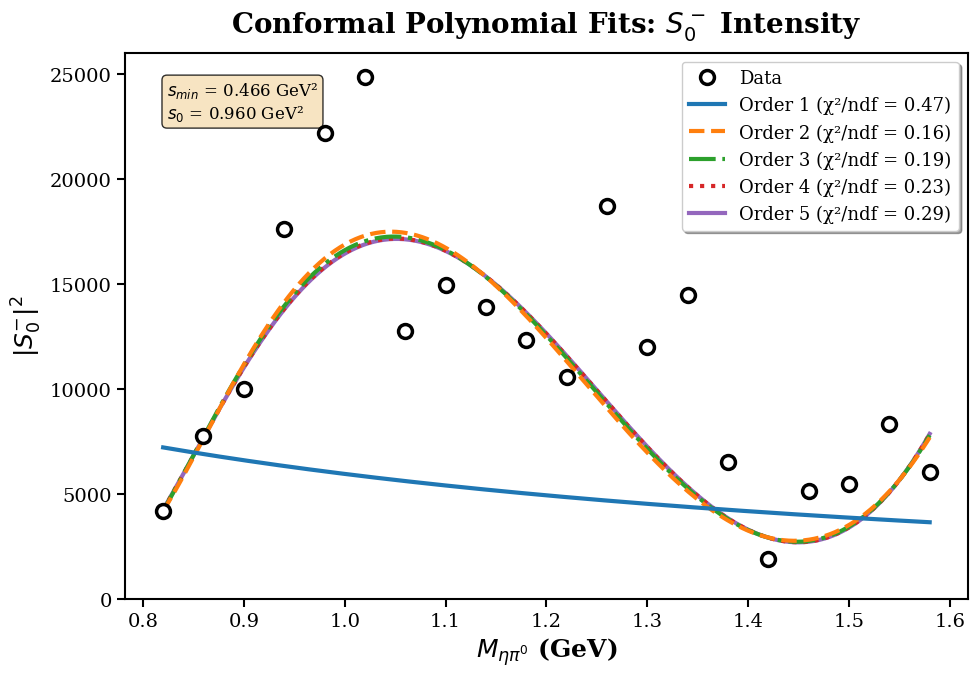

Saved: /d/home/septian/EtaPi0Plot/S0minus_polynomial_comparison.pdf
Saved: /d/home/septian/EtaPi0Plot/S0minus_polynomial_comparison.png


In [29]:
# Presentation plot 3: S_0^- magnitude fits - Single panel with all orders
fig, ax = plt.subplots(figsize=(10, 7))

# Plot data
ax.plot(masses, np.abs(b_complex)**2, 'o', color='black', markersize=10, 
        markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)

# Plot fits for each order
for idx, order in enumerate(orders_presentation):
    m_fine = fits_b[order]['m_fine']
    fit_fine = fits_b[order]['fit_fine']
    chi2_ndf = fits_b[order]['chi2_ndf']
    
    ax.plot(m_fine, np.abs(fit_fine)**2, 
            linestyle=linestyles[idx], linewidth=3, color=colors[idx],
            label=f'Order {order} (χ²/ndf = {chi2_ndf:.2f})', zorder=5-idx)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=18, fontweight='bold')
ax.set_ylabel(r'$|S_0^{-}|^2$', fontsize=18, fontweight='bold')
ax.set_title(r'Conformal Polynomial Fits: $S_0^-$ Intensity', fontsize=20, fontweight='bold', pad=15)

ax.legend(fontsize=13, loc='upper right', frameon=True, shadow=True, fancybox=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

# Add text box with fit parameters
textstr = f'$s_{{min}}$ = {s_min_phys:.3f} GeV²\n$s_0$ = {s_0_phys:.3f} GeV²'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.savefig(f'{out_pdf_dir}S0minus_polynomial_comparison.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}S0minus_polynomial_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}S0minus_polynomial_comparison.pdf")
print(f"Saved: {out_pdf_dir}S0minus_polynomial_comparison.png")


/tmp/ipykernel_1050940/803846856.py:51: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.tight_layout(rect=[0, 0, 1, 0.98])
/tmp/ipykernel_1050940/803846856.py:52: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0minus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1050940/803846856.py:52: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0minus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1050940/803846856.py:53: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.savefig(f'{out_pdf_dir}S0minus_polynomial_multipanel.png', dpi=300, bbox_inches='tight')
/d/home/septian/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


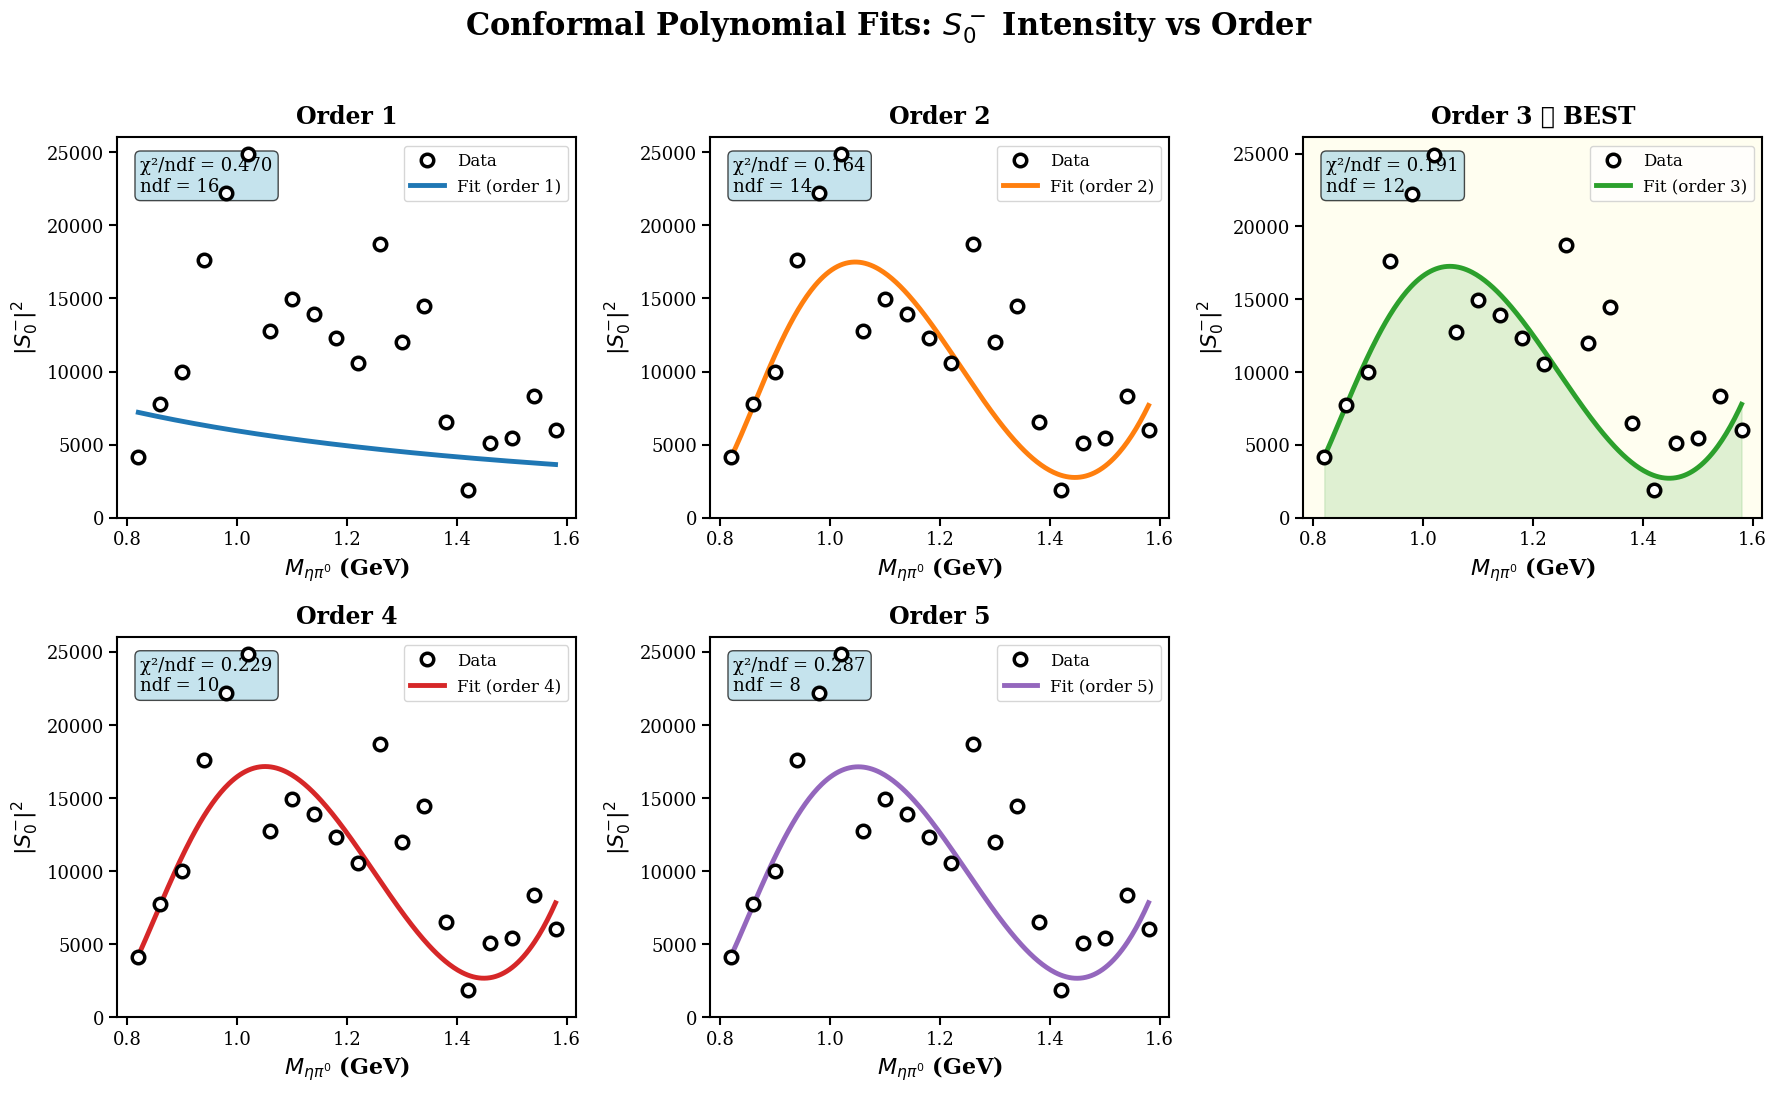

Saved: /d/home/septian/EtaPi0Plot/S0minus_polynomial_multipanel.pdf
Saved: /d/home/septian/EtaPi0Plot/S0minus_polynomial_multipanel.png


In [30]:
# Presentation plot 4: S_0^- Multi-panel comparison (2x3 grid)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, order in enumerate(orders_presentation):
    ax = axes[idx]
    m_fine = fits_b[order]['m_fine']
    fit_fine = fits_b[order]['fit_fine']
    chi2_ndf = fits_b[order]['chi2_ndf']
    ndf = fits_b[order]['ndf']
    
    # Plot data
    ax.plot(masses, np.abs(b_complex)**2, 'o', color='black', markersize=9, 
            markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)
    
    # Plot fit
    ax.plot(m_fine, np.abs(fit_fine)**2, '-', linewidth=3.5, color=colors[idx],
            label=f'Fit (order {order})', zorder=5)
    
    # Fill under curve for best fit
    if order == 3:
        ax.fill_between(m_fine, 0, np.abs(fit_fine)**2, alpha=0.15, color=colors[idx])
        ax.set_facecolor('#fffef0')  # Subtle highlight
    
    ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=16, fontweight='bold')
    ax.set_ylabel(r'$|S_0^{-}|^2$', fontsize=16, fontweight='bold')
    
    title_text = f'Order {order}'
    if order == 3:
        title_text += ' ★ BEST'
    ax.set_title(title_text, fontsize=17, fontweight='bold', pad=10)
    
    # Add chi2 info
    textstr = f'χ²/ndf = {chi2_ndf:.3f}\nndf = {ndf}'
    props = dict(boxstyle='round', facecolor='lightblue', alpha=0.7)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=13,
            verticalalignment='top', bbox=props)
    
    ax.legend(fontsize=12, loc='upper right', frameon=True)
    ax.grid(False)
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=13)

# Remove the 6th empty subplot
fig.delaxes(axes[5])

# Add overall title
fig.suptitle(r'Conformal Polynomial Fits: $S_0^-$ Intensity vs Order', 
             fontsize=22, fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig(f'{out_pdf_dir}S0minus_polynomial_multipanel.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}S0minus_polynomial_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}S0minus_polynomial_multipanel.pdf")
print(f"Saved: {out_pdf_dir}S0minus_polynomial_multipanel.png")


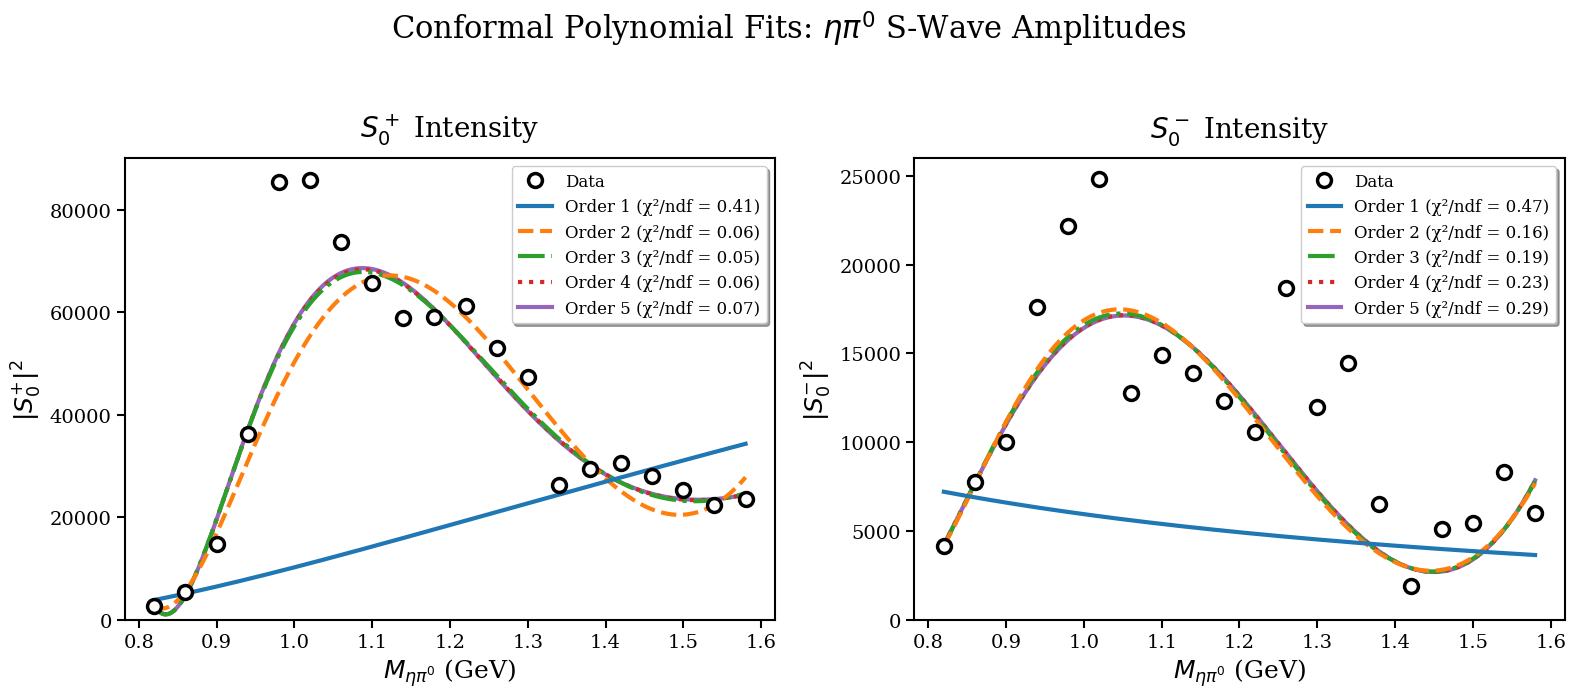

Saved: /d/home/septian/EtaPi0Plot/S0_amplitudes_sidebyside.pdf
Saved: /d/home/septian/EtaPi0Plot/S0_amplitudes_sidebyside.png


In [31]:
# Presentation plot 5: Side-by-side comparison of S_0^+ and S_0^-
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left panel: S_0^+
ax = axes[0]
ax.plot(masses, np.abs(a_complex)**2, 'o', color='black', markersize=10, 
        markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)

for idx, order in enumerate(orders_presentation):
    m_fine = fits_a[order]['m_fine']
    fit_fine = fits_a[order]['fit_fine']
    chi2_ndf = fits_a[order]['chi2_ndf']
    
    ax.plot(m_fine, np.abs(fit_fine)**2, 
            linestyle=linestyles[idx], linewidth=3, color=colors[idx],
            label=f'Order {order} (χ²/ndf = {chi2_ndf:.2f})', zorder=5-idx)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=18)
ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=18)
ax.set_title(r'$S_0^+$ Intensity', fontsize=20, pad=15)
ax.legend(fontsize=12, loc='upper right', frameon=True, shadow=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

# Right panel: S_0^-
ax = axes[1]
ax.plot(masses, np.abs(b_complex)**2, 'o', color='black', markersize=10, 
        markerfacecolor='white', markeredgewidth=2.5, label='Data', zorder=10)

for idx, order in enumerate(orders_presentation):
    m_fine = fits_b[order]['m_fine']
    fit_fine = fits_b[order]['fit_fine']
    chi2_ndf = fits_b[order]['chi2_ndf']
    
    ax.plot(m_fine, np.abs(fit_fine)**2, 
            linestyle=linestyles[idx], linewidth=3, color=colors[idx],
            label=f'Order {order} (χ²/ndf = {chi2_ndf:.2f})', zorder=5-idx)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=18)
ax.set_ylabel(r'$|S_0^{-}|^2$', fontsize=18)
ax.set_title(r'$S_0^-$ Intensity', fontsize=20, pad=15)
ax.legend(fontsize=12, loc='upper right', frameon=True, shadow=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

fig.suptitle(r'Conformal Polynomial Fits: $\eta\pi^0$ S-Wave Amplitudes', 
             fontsize=22, y=1.00)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f'{out_pdf_dir}S0_amplitudes_sidebyside.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}S0_amplitudes_sidebyside.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}S0_amplitudes_sidebyside.pdf")
print(f"Saved: {out_pdf_dir}S0_amplitudes_sidebyside.png")



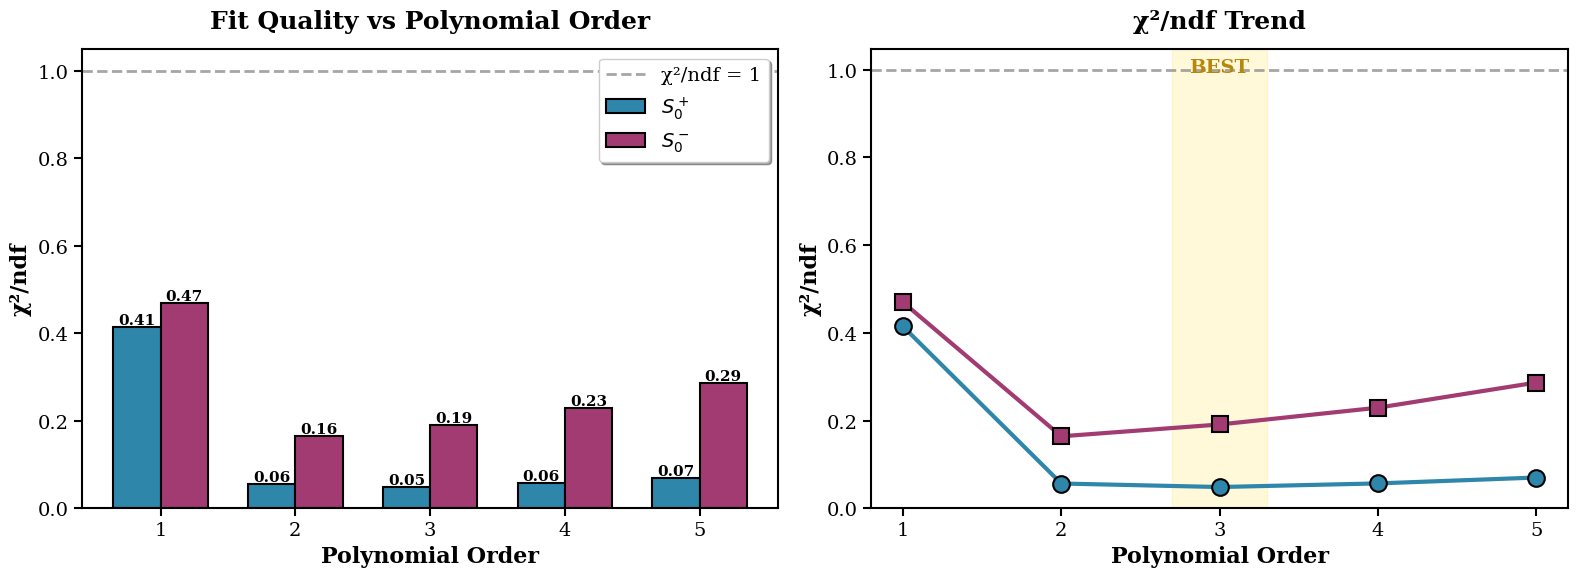

Saved: /d/home/septian/EtaPi0Plot/chi2_comparison.pdf
Saved: /d/home/septian/EtaPi0Plot/chi2_comparison.png

FIT QUALITY SUMMARY
Order    S₀⁺ χ²/ndf      S₀⁺ ndf    S₀⁻ χ²/ndf      S₀⁻ ndf   
--------------------------------------------------------------------------------
1        0.4147          16         0.4699          16        
2        0.0564          14         0.1641          14        
3        0.0484          12         0.1910          12          ★
4        0.0566          10         0.2293          10        
5        0.0700          8          0.2867          8         


In [32]:
# Presentation plot 6: Chi-square comparison summary
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Extract chi2/ndf values
orders_plot = list(orders_presentation)
chi2_a = [fits_a[o]['chi2_ndf'] for o in orders_plot]
chi2_b = [fits_b[o]['chi2_ndf'] for o in orders_plot]

# Left: Bar chart comparison
ax = axes[0]
x = np.arange(len(orders_plot))
width = 0.35

bars1 = ax.bar(x - width/2, chi2_a, width, label=r'$S_0^+$', 
               color='#2E86AB', edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, chi2_b, width, label=r'$S_0^-$', 
               color='#A23B72', edgecolor='black', linewidth=1.5)

ax.axhline(1.0, color='gray', linestyle='--', linewidth=2, alpha=0.7, label='χ²/ndf = 1')
ax.set_xlabel('Polynomial Order', fontsize=16, fontweight='bold')
ax.set_ylabel('χ²/ndf', fontsize=16, fontweight='bold')
ax.set_title('Fit Quality vs Polynomial Order', fontsize=18, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(orders_plot)
ax.legend(fontsize=14, loc='upper right', frameon=True, shadow=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Right: Line plot
ax = axes[1]
ax.plot(orders_plot, chi2_a, 'o-', linewidth=3, markersize=12, 
        color='#2E86AB', label=r'$S_0^+$', markeredgecolor='black', markeredgewidth=1.5)
ax.plot(orders_plot, chi2_b, 's-', linewidth=3, markersize=12, 
        color='#A23B72', label=r'$S_0^-$', markeredgecolor='black', markeredgewidth=1.5)

ax.axhline(1.0, color='gray', linestyle='--', linewidth=2, alpha=0.7)
ax.set_xlabel('Polynomial Order', fontsize=16, fontweight='bold')
ax.set_ylabel('χ²/ndf', fontsize=16, fontweight='bold')
ax.set_title('χ²/ndf Trend', fontsize=18, fontweight='bold', pad=15)
ax.set_xticks(orders_plot)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=14)

# Highlight best order (order 3)
ax.axvspan(2.7, 3.3, alpha=0.15, color='gold', zorder=0)
ax.text(3, ax.get_ylim()[1]*0.95, 'BEST', ha='center', fontsize=14, 
        fontweight='bold', color='darkgoldenrod')

plt.tight_layout()
plt.savefig(f'{out_pdf_dir}chi2_comparison.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}chi2_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: {out_pdf_dir}chi2_comparison.pdf")
print(f"Saved: {out_pdf_dir}chi2_comparison.png")

# Print summary table
print("\n" + "="*80)
print("FIT QUALITY SUMMARY")
print("="*80)
print(f"{'Order':<8} {'S₀⁺ χ²/ndf':<15} {'S₀⁺ ndf':<10} {'S₀⁻ χ²/ndf':<15} {'S₀⁻ ndf':<10}")
print("-"*80)
for order in orders_presentation:
    marker = "  ★" if order == 3 else ""
    print(f"{order:<8} {fits_a[order]['chi2_ndf']:<15.4f} {fits_a[order]['ndf']:<10} "
          f"{fits_b[order]['chi2_ndf']:<15.4f} {fits_b[order]['ndf']:<10}{marker}")
print("="*80)



In [33]:
# Fit with Flatté amplitude + conformal polynomial (order 3)
# Flatté parameterizes the a_0(980) resonance with coupled-channel effects

import numpy as np
from scipy.optimize import minimize

def flatte_amplitude(s, m0, g_etapi, g_KK):
    """
    Flatté amplitude for a_0(980) resonance.
    
    Parameters:
    -----------
    s : float or array
        Invariant mass squared (GeV²)
    m0 : float
        Resonance mass (GeV)
    g_etapi : float
        Coupling to ηπ channel
    g_KK : float
        Coupling to KK channel
    
    Returns:
    --------
    amplitude : complex
        Flatté amplitude
    """
    m_eta = 0.547862  # GeV
    m_pi0 = 0.1349766  # GeV
    m_K = 0.493677  # GeV (charged K)
    
    # Threshold for ηπ
    s_etapi = (m_eta + m_pi0)**2
    
    # Threshold for KK
    s_KK = (2 * m_K)**2
    
    # Phase space factors (ρ)
    # For ηπ channel
    if np.isscalar(s):
        if s > s_etapi:
            rho_etapi = np.sqrt(1 - s_etapi / s)
        else:
            rho_etapi = 1j * np.sqrt(s_etapi / s - 1)
    else:
        rho_etapi = np.where(s > s_etapi, 
                             np.sqrt(1 - s_etapi / s),
                             1j * np.sqrt(s_etapi / s - 1))
    
    # For KK channel
    if np.isscalar(s):
        if s > s_KK:
            rho_KK = np.sqrt(1 - s_KK / s)
        else:
            rho_KK = 1j * np.sqrt(s_KK / s - 1)
    else:
        rho_KK = np.where(s > s_KK, 
                         np.sqrt(1 - s_KK / s),
                         1j * np.sqrt(s_KK / s - 1))
    
    # Flatté denominator: m0² - s - i*m0*(g_etapi²*ρ_ηπ + g_KK²*ρ_KK)
    denominator = m0**2 - s - 1j * m0 * (g_etapi**2 * rho_etapi + g_KK**2 * rho_KK)
    
    # Amplitude (normalized by coupling)
    amplitude = g_etapi / denominator
    
    return amplitude


print("="*70)
print(f"Model: A(s) = scale * A_Flatté(s) + Σ(c_i * z^i)  [i=0 to 3]")
print(f"Flatté parameters: scale, m0, g_ηπ, g_KK")
print(f"Model: A(s) = A_Flatté(s) + Σ(c_i * z^i)  [i=0 to 3]")
print(f"Total parameters: 12")
print(f"Polynomial parameters: 4 complex coefficients (8 real parameters)")
print(f"Total parameters: 11")
print("="*70)

Model: A(s) = scale * A_Flatté(s) + Σ(c_i * z^i)  [i=0 to 3]
Flatté parameters: scale, m0, g_ηπ, g_KK
Model: A(s) = A_Flatté(s) + Σ(c_i * z^i)  [i=0 to 3]
Total parameters: 12
Polynomial parameters: 4 complex coefficients (8 real parameters)
Total parameters: 11


In [184]:
# Combined fit with shared Flatté couplings between S_0^+ and S_0^-
print("\n" + "="*80)
print("COMBINED FIT: Shared g_ηπ and g_KK between S₀⁺ and S₀⁻")
print("="*80)

def combined_chi2(params, z, s, data_a, data_b):
    """
    Combined chi-squared for S_0^+ and S_0^- with shared Flatté couplings.
    
    Parameters:
    -----------
    params : array
        [g_etapi, g_KK, scale_a, scale_b, poly_a_coeffs (8), poly_b_coeffs (8)]
        - g_etapi, g_KK: shared coupling parameters
        - scale_a, scale_b: individual scale factors
        - poly_a_coeffs: 4 complex coefficients for S_0^+ (8 real params)
        - poly_b_coeffs: 4 complex coefficients for S_0^- (8 real params)
    
    Total: 2 + 2 + 8 + 8 = 20 parameters
    """
    m0 = 0.98  # Fixed resonance mass
    
    # Extract parameters
    g_etapi = params[0]
    g_KK = params[1]
    scale_a = params[2]
    scale_b = params[3]
    
    n_coeffs = 4  # Order 3 polynomial
    poly_a = params[4:4+2*n_coeffs]
    poly_b = params[4+2*n_coeffs:]
    
    # Compute Flatté amplitude (shared couplings)
    A_flatte_base = np.array([flatte_amplitude(s[i], m0, g_etapi, g_KK) for i in range(len(s))])
    
    # Compute S_0^+ amplitude
    A_poly_a = np.zeros_like(z, dtype=complex)
    for i in range(n_coeffs):
        A_poly_a += (poly_a[i] + 1j * poly_a[n_coeffs + i]) * z**i
    A_total_a = scale_a*np.abs(A_flatte_base)**2 + np.abs(A_poly_a)**2
    
    # Compute S_0^- amplitude
    A_poly_b = np.zeros_like(z, dtype=complex)
    for i in range(n_coeffs):
        A_poly_b += (poly_b[i] + 1j * poly_b[n_coeffs + i]) * z**i
    A_total_b = scale_b*np.abs(A_flatte_base)**2 + np.abs(A_poly_b)**2
    
    # Chi-squared for both waves
    residuals_a = (A_total_a - np.abs(data_a)**2) / np.abs(data_a)**2
    residuals_b = (A_total_b - np.abs(data_b)**2) / np.abs(data_b)**2
    
    chi2_a = np.sum(residuals_a**2)
    chi2_b = np.sum(residuals_b**2)
    
    return chi2_a + chi2_b

# Initial parameters
order = 3
n_coeffs = order + 1

# Estimate scales
data_at_res_a = np.abs(a_complex[np.argmin(np.abs(masses - 0.98))])**2
scale_init_a = 10000

data_at_res_b = np.abs(b_complex[np.argmin(np.abs(masses - 0.98))])**2
scale_init_b = 10000
# scale_init_b = 150

# Get polynomial initial values
poly_init_a = fits_a[order]['params']
poly_init_b = fits_b[order]['params']

# Combined initial parameters: [g_etapi, g_KK, scale_a, scale_b, poly_a, poly_b]
initial_params_combined = np.zeros(4 + len(poly_init_a) + len(poly_init_b))
initial_params_combined[0] = 1 # g_etapi
initial_params_combined[1] = 0.3   # g_KK
initial_params_combined[2] = scale_init_a
initial_params_combined[3] = scale_init_b
initial_params_combined[4:4+len(poly_init_a)] = poly_init_a
initial_params_combined[4+len(poly_init_a):] = poly_init_b

print(f"Initial parameters:")
print(f"  g_ηπ    = {initial_params_combined[0]:.4f} GeV")
print(f"  g_KK    = {initial_params_combined[1]:.4f} GeV")
print(f"  scale_a = {initial_params_combined[2]:.4f}")
print(f"  scale_b = {initial_params_combined[3]:.4f}")
print(f"  Number of parameters: {len(initial_params_combined)}")
print(f"    - Shared Flatté couplings: 2")
print(f"    - Individual scales: 2")
print(f"    - S₀⁺ polynomial: {len(poly_init_a)}")
print(f"    - S₀⁻ polynomial: {len(poly_init_b)}")

# Fit with L-BFGS-B
print("\nOptimizing with L-BFGS-B...")
result_combined = minimize(
    combined_chi2,
    initial_params_combined,
    args=(z_phys, masses**2, a_complex, b_complex),
    method='L-BFGS-B',
    bounds=[(0.5, 3.0),     # g_etapi: shared
            (0.1, 2.0),     # g_KK: shared
            (300, 100000),    # scale_a
            (300, 50000),    # scale_b
            *[(None, None)] * (len(poly_init_a) + len(poly_init_b))],  # polynomials
    options={'maxiter': 50000, 'ftol': 1e-12}
)

print(f"  L-BFGS-B: χ²_total = {result_combined.fun:.2f}, success = {result_combined.success}")

# Extract results
g_etapi_shared = result_combined.x[0]
g_KK_shared = result_combined.x[1]
scale_a_fit = result_combined.x[2]
scale_b_fit = result_combined.x[3]
poly_a_fit = result_combined.x[4:4+len(poly_init_a)]
poly_b_fit = result_combined.x[4+len(poly_init_a):]

# Compute individual chi-squared values
m0_fixed = 0.98
A_flatte_shared = np.array([flatte_amplitude(masses[i]**2, m0_fixed, g_etapi_shared, g_KK_shared) for i in range(len(masses))])

# S_0^+
A_poly_a_fit = np.zeros_like(z_phys, dtype=complex)
for i in range(n_coeffs):
    A_poly_a_fit += (poly_a_fit[i] + 1j * poly_a_fit[n_coeffs + i]) * z_phys**i
A_total_a_fit = scale_a_fit * np.abs(A_flatte_shared)**2 + np.abs(A_poly_a_fit)**2

residuals_a = (A_total_a_fit - np.abs(a_complex)**2) / np.abs(a_complex)**2
chi2_a = np.sum(residuals_a**2)

# S_0^-
A_poly_b_fit = np.zeros_like(z_phys, dtype=complex)
for i in range(n_coeffs):
    A_poly_b_fit += (poly_b_fit[i] + 1j * poly_b_fit[n_coeffs + i]) * z_phys**i
A_total_b_fit = scale_b_fit * np.abs(A_flatte_shared)**2 + np.abs(A_poly_b_fit)**2

residuals_b = (A_total_b_fit - np.abs(b_complex)**2) / np.abs(b_complex)**2
chi2_b = np.sum(residuals_b**2)

# Degrees of freedom
n_data = len(masses)
n_params = len(initial_params_combined)
ndf_a = n_data - n_params
ndf_b = n_data - n_params
ndf_total = 2 * n_data - n_params

chi2_ndf_a = chi2_a / ndf_a
chi2_ndf_b = chi2_b / ndf_b
chi2_ndf_total = result_combined.fun / ndf_total

print("\n" + "="*80)
print("FITTED PARAMETERS (SHARED COUPLINGS):")
print("="*80)
print(f"Shared Flatté parameters:")
print(f"  m0      = {m0_fixed:.4f} GeV (fixed)")
print(f"  g_ηπ    = {g_etapi_shared:.4f} GeV")
print(f"  g_KK    = {g_KK_shared:.4f} GeV")
print(f"\nIndividual parameters:")
print(f"  scale_a = {scale_a_fit:.4f} (S₀⁺)")
print(f"  scale_b = {scale_b_fit:.4f} (S₀⁻)")
print(f"\nFit quality:")
print(f"  S₀⁺: χ² = {chi2_a:.2f}, ndf = {ndf_a}, χ²/ndf = {chi2_ndf_a:.4f}")
print(f"  S₀⁻: χ² = {chi2_b:.2f}, ndf = {ndf_b}, χ²/ndf = {chi2_ndf_b:.4f}")
print(f"  Total: χ² = {result_combined.fun:.2f}, ndf = {ndf_total}, χ²/ndf = {chi2_ndf_total:.4f}")
print("="*80)

# Store results
fit_shared = {
    'chi2_total': result_combined.fun,
    'chi2_a': chi2_a,
    'chi2_b': chi2_b,
    'chi2_ndf_total': chi2_ndf_total,
    'chi2_ndf_a': chi2_ndf_a,
    'chi2_ndf_b': chi2_ndf_b,
    'ndf_total': ndf_total,
    'ndf_a': ndf_a,
    'ndf_b': ndf_b,
    'params': result_combined.x,
    'g_etapi': g_etapi_shared,
    'g_KK': g_KK_shared,
    'm0': m0_fixed,
    'scale_a': scale_a_fit,
    'scale_b': scale_b_fit,
    'poly_a': poly_a_fit,
    'poly_b': poly_b_fit
}


COMBINED FIT: Shared g_ηπ and g_KK between S₀⁺ and S₀⁻
Initial parameters:
  g_ηπ    = 1.0000 GeV
  g_KK    = 0.3000 GeV
  scale_a = 10000.0000
  scale_b = 10000.0000
  Number of parameters: 20
    - Shared Flatté couplings: 2
    - Individual scales: 2
    - S₀⁺ polynomial: 8
    - S₀⁻ polynomial: 8

Optimizing with L-BFGS-B...
  L-BFGS-B: χ²_total = 2.99, success = False

FITTED PARAMETERS (SHARED COUPLINGS):
Shared Flatté parameters:
  m0      = 0.9800 GeV (fixed)
  g_ηπ    = 3.0000 GeV
  g_KK    = 2.0000 GeV

Individual parameters:
  scale_a = 6258.4388 (S₀⁺)
  scale_b = 9870.7072 (S₀⁻)

Fit quality:
  S₀⁺: χ² = 0.65, ndf = 0, χ²/ndf = inf
  S₀⁻: χ² = 2.34, ndf = 0, χ²/ndf = inf
  Total: χ² = 2.99, ndf = 20, χ²/ndf = 0.1493


/tmp/ipykernel_1050940/4285923118.py:147: RuntimeWarning: divide by zero encountered in scalar divide
  chi2_ndf_a = chi2_a / ndf_a
/tmp/ipykernel_1050940/4285923118.py:148: RuntimeWarning: divide by zero encountered in scalar divide
  chi2_ndf_b = chi2_b / ndf_b


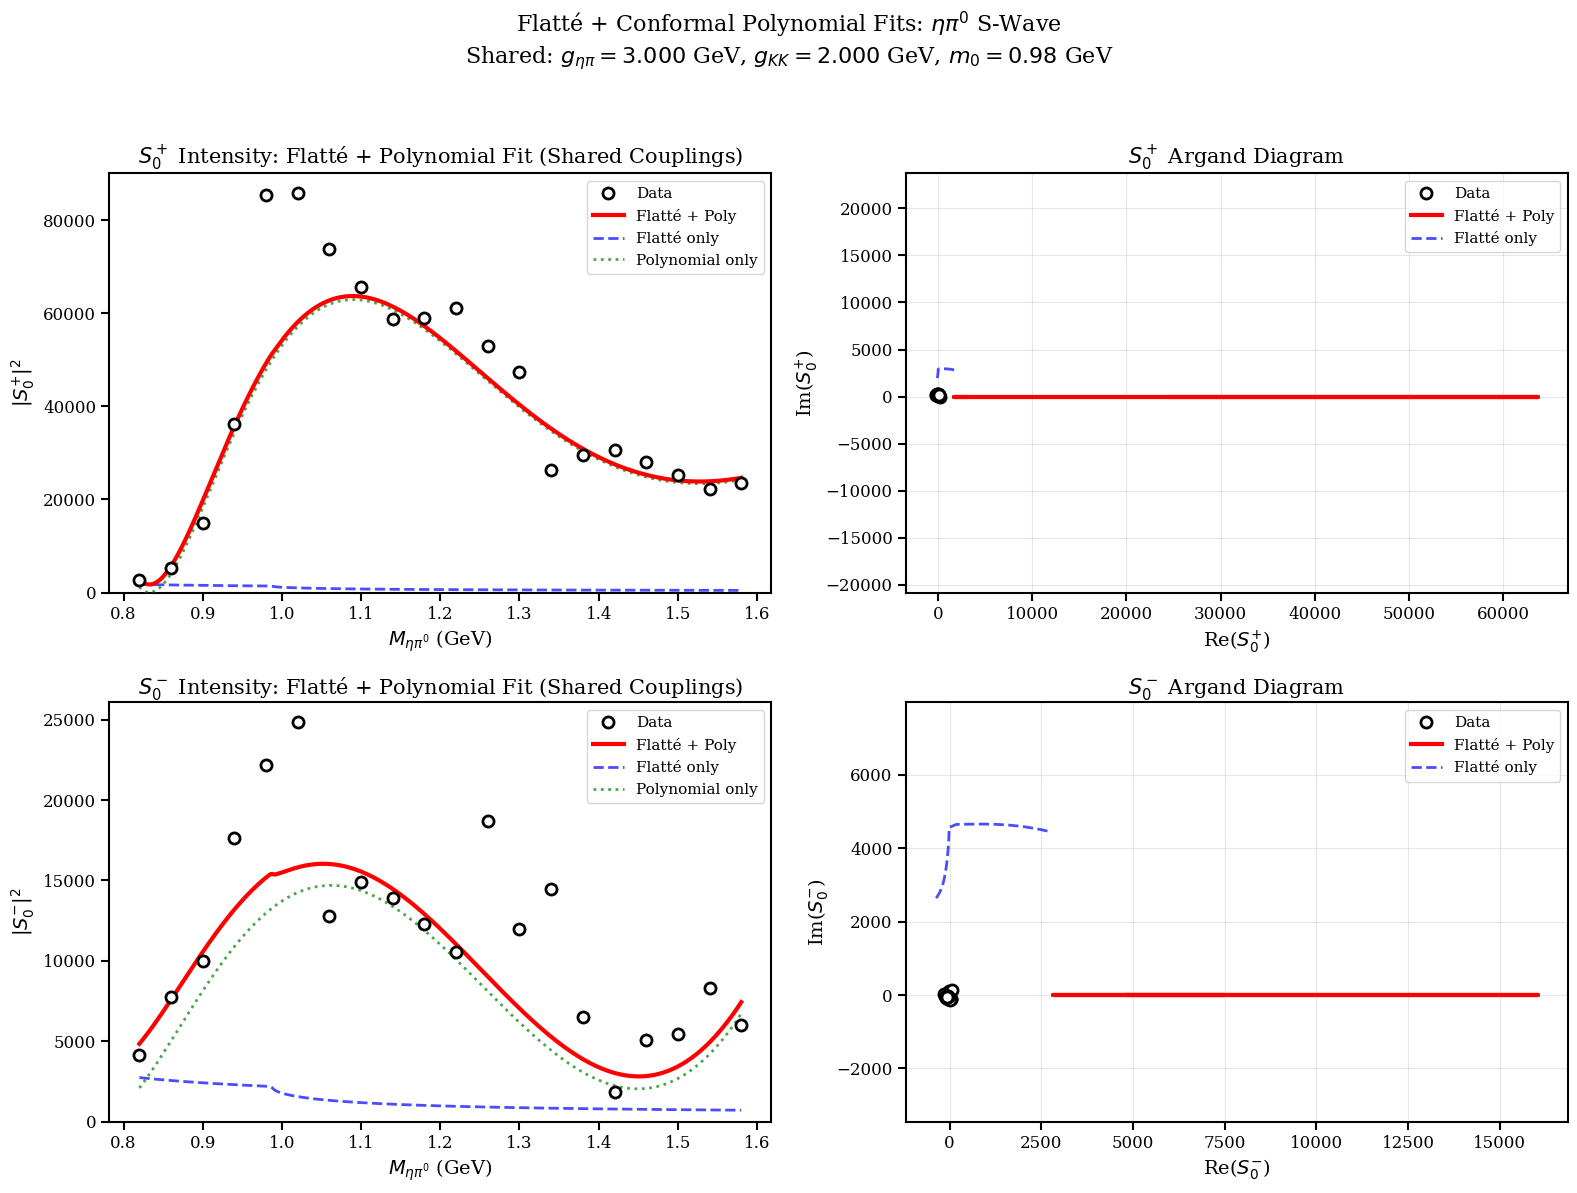


Saved: /d/home/septian/EtaPi0Plot/flatte_poly_fits_shared.pdf
Saved: /d/home/septian/EtaPi0Plot/flatte_poly_fits_shared.png


In [185]:
# Visualize Flatté + polynomial fits with shared couplings
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Evaluate fitted models on fine grid
m_fine = np.linspace(masses.min(), masses.max(), 300)
s_fine = m_fine**2
z_fine = conformal_map(s_fine, s_min_phys, s_0_phys)

# Extract shared parameters
g_etapi_shared = fit_shared['g_etapi']
g_KK_shared = fit_shared['g_KK']
m0_shared = fit_shared['m0']
scale_a = fit_shared['scale_a']
scale_b = fit_shared['scale_b']
poly_a = fit_shared['poly_a']
poly_b = fit_shared['poly_b']

# Compute Flatté amplitude (shared)
A_flatte_fine = np.array([flatte_amplitude(s_fine[i], m0_shared, g_etapi_shared, g_KK_shared) 
                          for i in range(len(s_fine))])

# === S_0^+ fits ===
n_coeffs = 4
a_coeffs_a = poly_a[:n_coeffs]
b_coeffs_a = poly_a[n_coeffs:]

A_poly_a = np.zeros_like(z_fine, dtype=complex)
for i in range(n_coeffs):
    A_poly_a += (a_coeffs_a[i] + 1j * b_coeffs_a[i]) * z_fine**i
A_total_a = scale_a * np.abs(A_flatte_fine)**2 + np.abs(A_poly_a)**2

# === S_0^- fits ===
a_coeffs_b = poly_b[:n_coeffs]
b_coeffs_b = poly_b[n_coeffs:]

A_poly_b = np.zeros_like(z_fine, dtype=complex)
for i in range(n_coeffs):
    A_poly_b += (a_coeffs_b[i] + 1j * b_coeffs_b[i]) * z_fine**i
A_total_b = scale_b * np.abs(A_flatte_fine)**2 + np.abs(A_poly_b)**2

# Plot 1: S_0^+ intensity
ax = axes[0, 0]
ax.plot(masses, np.abs(a_complex)**2, 'ko', markersize=8, 
        markerfacecolor='white', markeredgewidth=2, label='Data', zorder=10)
ax.plot(m_fine, np.abs(A_total_a), 'r-', linewidth=3, 
        label=f'Flatté + Poly', zorder=8)
ax.plot(m_fine, scale_a * np.abs(A_flatte_fine)**2, 'b--', linewidth=2, alpha=0.7,
        label=f'Flatté only', zorder=7)
ax.plot(m_fine, np.abs(A_poly_a)**2, 'g:', linewidth=2, alpha=0.7,
        label='Polynomial only', zorder=6)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=14)
ax.set_ylabel(r'$|S_0^{+}|^2$', fontsize=14)
ax.set_title(r'$S_0^+$ Intensity: Flatté + Polynomial Fit (Shared Couplings)', fontsize=15)
ax.legend(fontsize=11, loc='upper right', frameon=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=12)

# Plot 2: S_0^+ Argand diagram
ax = axes[0, 1]
ax.plot(a_complex.real, a_complex.imag, 'ko', markersize=8,
        markerfacecolor='white', markeredgewidth=2, label='Data', zorder=10)
ax.plot(A_total_a.real, A_total_a.imag, 'r-', linewidth=3, label='Flatté + Poly', zorder=8)
ax.plot((scale_a * A_flatte_fine).real, (scale_a * A_flatte_fine).imag, 'b--', 
        linewidth=2, alpha=0.7, label='Flatté only', zorder=7)
ax.set_xlabel(r'Re($S_0^{+}$)', fontsize=14)
ax.set_ylabel(r'Im($S_0^{+}$)', fontsize=14)
ax.set_title(r'$S_0^+$ Argand Diagram', fontsize=15)
ax.legend(fontsize=11, loc='best', frameon=True)
ax.grid(True, alpha=0.3)
ax.axis('equal')
ax.tick_params(labelsize=12)

# Plot 3: S_0^- intensity
ax = axes[1, 0]
ax.plot(masses, np.abs(b_complex)**2, 'ko', markersize=8,
        markerfacecolor='white', markeredgewidth=2, label='Data', zorder=10)
ax.plot(m_fine, np.abs(A_total_b), 'r-', linewidth=3,
        label=f'Flatté + Poly', zorder=8)
ax.plot(m_fine, scale_b * np.abs(A_flatte_fine)**2, 'b--', linewidth=2, alpha=0.7,
        label=f'Flatté only', zorder=7)
ax.plot(m_fine, np.abs(A_poly_b)**2, 'g:', linewidth=2, alpha=0.7,
        label='Polynomial only', zorder=6)

ax.set_xlabel(r'$M_{\eta\pi^0}$ (GeV)', fontsize=14)
ax.set_ylabel(r'$|S_0^{-}|^2$', fontsize=14)
ax.set_title(r'$S_0^-$ Intensity: Flatté + Polynomial Fit (Shared Couplings)', fontsize=15)
ax.legend(fontsize=11, loc='upper right', frameon=True)
ax.grid(False)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=12)

# Plot 4: S_0^- Argand diagram
ax = axes[1, 1]
ax.plot(b_complex.real, b_complex.imag, 'ko', markersize=8,
        markerfacecolor='white', markeredgewidth=2, label='Data', zorder=10)
ax.plot(A_total_b.real, A_total_b.imag, 'r-', linewidth=3, label='Flatté + Poly', zorder=8)
ax.plot((scale_b * A_flatte_fine).real, (scale_b * A_flatte_fine).imag, 'b--', 
        linewidth=2, alpha=0.7, label='Flatté only', zorder=7)
ax.set_xlabel(r'Re($S_0^{-}$)', fontsize=14)
ax.set_ylabel(r'Im($S_0^{-}$)', fontsize=14)
ax.set_title(r'$S_0^-$ Argand Diagram', fontsize=15)
ax.legend(fontsize=11, loc='best', frameon=True)
ax.grid(True, alpha=0.3)
ax.axis('equal')
ax.tick_params(labelsize=12)

# Add shared parameters info to title
fig.suptitle(f'Flatté + Conformal Polynomial Fits: $\\eta\\pi^0$ S-Wave\n' + 
             f'Shared: $g_{{\\eta\\pi}}={g_etapi_shared:.3f}$ GeV, $g_{{KK}}={g_KK_shared:.3f}$ GeV, ' +
             f'$m_0={m0_shared:.2f}$ GeV', 
             fontsize=16, y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f'{out_pdf_dir}flatte_poly_fits_shared.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{out_pdf_dir}flatte_poly_fits_shared.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nSaved: {out_pdf_dir}flatte_poly_fits_shared.pdf")
print(f"Saved: {out_pdf_dir}flatte_poly_fits_shared.png")

In [186]:
# # Comparison table: Pure polynomial vs Flatté + polynomial
# print("\n" + "="*80)
# print("FIT COMPARISON: PURE POLYNOMIAL vs FLATTÉ + POLYNOMIAL")
# print("="*80)
# print(f"{'Wave':<8} {'Model':<20} {'χ²':<12} {'ndf':<8} {'χ²/ndf':<12} {'Δχ²/ndf':<12}")
# print("-"*80)

# # S_0^+
# chi2_pure_a = fits_a[3]['chi2']
# chi2_ndf_pure_a = fits_a[3]['chi2_ndf']
# ndf_pure_a = fits_a[3]['ndf']

# chi2_flatte_a = fit_flatte_poly_a['chi2']
# chi2_ndf_flatte_a = fit_flatte_poly_a['chi2_ndf']
# ndf_flatte_a = fit_flatte_poly_a['ndf']

# delta_chi2_ndf_a = chi2_ndf_pure_a - chi2_ndf_flatte_a

# print(f"{'S₀⁺':<8} {'Pure Poly (order 3)':<20} {chi2_pure_a:<12.2f} {ndf_pure_a:<8} {chi2_ndf_pure_a:<12.4f} {'-':<12}")
# print(f"{'S₀⁺':<8} {'Flatté + Poly':<20} {chi2_flatte_a:<12.2f} {ndf_flatte_a:<8} {chi2_ndf_flatte_a:<12.4f} {delta_chi2_ndf_a:<12.4f}")
# print()

# # S_0^-
# chi2_pure_b = fits_b[3]['chi2']
# chi2_ndf_pure_b = fits_b[3]['chi2_ndf']
# ndf_pure_b = fits_b[3]['ndf']

# chi2_flatte_b = fit_flatte_poly_b['chi2']
# chi2_ndf_flatte_b = fit_flatte_poly_b['chi2_ndf']
# ndf_flatte_b = fit_flatte_poly_b['ndf']

# delta_chi2_ndf_b = chi2_ndf_pure_b - chi2_ndf_flatte_b

# print(f"{'S₀⁻':<8} {'Pure Poly (order 3)':<20} {chi2_pure_b:<12.2f} {ndf_pure_b:<8} {chi2_ndf_pure_b:<12.4f} {'-':<12}")
# print(f"{'S₀⁻':<8} {'Flatté + Poly':<20} {chi2_flatte_b:<12.2f} {ndf_flatte_b:<8} {chi2_ndf_flatte_b:<12.4f} {delta_chi2_ndf_b:<12.4f}")
# print("="*80)

# print("\nInterpretation:")
# if delta_chi2_ndf_a > 0:
#     print(f"  S₀⁺: Flatté+Poly improves fit by Δχ²/ndf = {delta_chi2_ndf_a:.4f}")
# else:
#     print(f"  S₀⁺: Pure polynomial gives better fit by Δχ²/ndf = {-delta_chi2_ndf_a:.4f}")
    
# if delta_chi2_ndf_b > 0:
#     print(f"  S₀⁻: Flatté+Poly improves fit by Δχ²/ndf = {delta_chi2_ndf_b:.4f}")
# else:
#     print(f"  S₀⁻: Pure polynomial gives better fit by Δχ²/ndf = {-delta_chi2_ndf_b:.4f}")

# print("\nFlatté parameters:")
# print(f"  S₀⁺: m₀ = {fit_flatte_poly_a['m0']:.4f} GeV, g_ηπ = {fit_flatte_poly_a['g_etapi']:.4f} GeV, g_KK = {fit_flatte_poly_a['g_KK']:.4f} GeV")
# print(f"  S₀⁻: m₀ = {fit_flatte_poly_b['m0']:.4f} GeV, g_ηπ = {fit_flatte_poly_b['g_etapi']:.4f} GeV, g_KK = {fit_flatte_poly_b['g_KK']:.4f} GeV")
# print(f"\nPDG a₀(980): m = 0.980 ± 0.020 GeV (for reference)")
# print("="*80)